In [97]:
import pandas as pd


In [98]:
# 1.1 Load training dataset
training_set = pd.read_csv("/Users/suyogtimalsina/Desktop/Drug-Induced Autoimmunity Prediction/drug_induced_autoimmunity_prediction (1)/DIA_trainingset_RDKit_descriptors.csv")
training_set

,Label,SMILES,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,0,COC(=O)N(C)c1c(N)nc(nc1N)c2nn(Cc3ccccc3F)c4ncc...,1.821,1266.407,22.121,16.781,16.781,14.901,9.203,9.203,...,0,0,0,0,0,0,0,0,0,0
1,0,C[C@H](N(O)C(=O)N)c1cc2ccccc2s1,2.363,490.434,11.707,8.752,9.569,7.592,4.854,5.670,...,0,0,0,0,0,0,0,1,0,1
2,0,C[N+](C)(C)CC(=O)[O-],3.551,93.092,6.784,5.471,5.471,3.417,2.420,2.420,...,0,0,0,0,0,0,0,0,0,0
3,1,CC(C)n1c(\C=C\[C@H](O)C[C@H](O)CC(=O)O)c(c2ccc...,2.076,1053.003,21.836,16.995,16.995,14.274,9.926,9.926,...,0,0,0,0,0,0,0,0,0,0
4,1,C\C(=C(\C#N)/C(=O)Nc1ccc(cc1)C(F)(F)F)\O,2.888,549.823,14.629,9.746,9.746,8.752,5.040,5.040,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
472,0,C(C1=NCCN1)c2cccc3ccccc23,2.022,537.932,10.795,9.110,9.110,7.933,5.672,5.672,...,0,0,0,0,0,0,0,0,0,0
473,0,C[N@+]1(CC2CC2)CC[C@]34[C@H]5Oc6c(O)ccc(C[C@@H...,1.602,848.658,17.897,15.202,15.202,12.389,10.003,10.003,...,0,0,0,0,0,0,0,0,0,0
474,1,CO\N=C(/C(=O)N[C@H]1[C@H]2SCC(=C(N2C1=O)C(=O)O...,1.766,910.031,21.129,14.986,15.802,13.845,8.129,9.178,...,1,0,0,0,0,0,0,0,0,0
475,0,Clc1ccc(CO\N=C(\Cn2ccnc2)/c3ccc(Cl)cc3Cl)c(Cl)c1,1.831,926.191,18.518,13.372,16.396,12.525,7.566,9.078,...,0,0,0,0,0,0,0,0,0,0


In [99]:
Xtrain = training_set.iloc[:, 2:] # Select all rows and columns from the 3rd column onward
Ytrain = training_set.iloc[:, 0]

In [100]:
# Display label distribution
print(Ytrain.value_counts())

Label
0    359
1    118
Name: count, dtype: int64


In [101]:
# 1.2 Load test dataset
test_set = pd.read_csv("/Users/suyogtimalsina/Desktop/Drug-Induced Autoimmunity Prediction/drug_induced_autoimmunity_prediction (1)/DIA_testset_RDKit_descriptors.csv")
test_set

,Label,SMILES,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,0,C[C@H](\C=C\[C@H](O)C1CC1)[C@@H]2CC[C@@H]3\C(=...,1.484,743.207,21.466,18.764,18.764,14.292,12.106,12.106,...,0,0,0,0,0,0,0,0,0,0
1,1,OCCN1CCN(CCCN2c3ccccc3Sc4ccc(cc24)C(F)(F)F)CC1,1.472,868.947,21.140,16.736,17.553,14.453,10.268,11.084,...,0,0,0,0,0,0,0,0,0,0
2,0,C[C@@H]1O[C@H](C[C@H](O)[C@@H]1O)O[C@@H]2[C@H]...,0.837,1409.004,39.189,32.904,32.904,26.011,20.941,20.941,...,0,0,0,0,0,0,0,0,0,0
3,1,NC(=O)Cc1cccc(C(=O)c2ccccc2)c1N,2.406,621.298,13.828,10.297,10.297,9.092,5.847,5.847,...,0,0,0,0,0,0,0,0,0,0
4,0,COc1cc2c(CCN[C@]23CS[C@@H]4[C@@H]5[C@@H]6N(C)[...,1.320,2127.996,37.955,30.849,31.666,25.910,18.066,19.115,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,0,CCN1CCN(C(=O)N[C@H](C(=O)N[C@@H]2[C@@H]3SC(C)(...,1.508,1127.109,26.361,19.925,20.742,16.973,11.450,12.330,...,1,0,0,0,0,0,0,0,0,1
116,0,CC1=C(C=C(C#N)C(=O)N1)c2ccncc2,2.678,608.396,11.544,8.689,8.689,7.720,4.765,4.765,...,0,0,0,0,0,0,0,0,0,0
117,0,CCCN(CCc1cccs1)[C@@H]2CCc3c(O)cccc3C2,1.670,593.488,15.364,13.294,14.110,10.775,8.338,9.217,...,0,0,0,0,0,0,0,1,0,0
118,0,COCCOC(=O)C1=C(C)NC(=C([C@@H]1c2cccc(c2)[N+](=...,2.603,902.371,22.422,17.683,17.683,14.167,9.469,9.469,...,0,0,0,0,0,0,0,0,1,0


In [102]:
Xtest = test_set.iloc[:, 2:]
Ytest = test_set.iloc[:, 0]

In [103]:
# Display label distribution
print(Ytest.value_counts())

Label
0    90
1    30
Name: count, dtype: int64


In [104]:
Xtrain.index

RangeIndex(start=0, stop=477, step=1)

In [105]:
# 2. Feature preprocessing pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
import numpy as np
import joblib

def preprocess_features(X_train,X_test):
    
    # 2.1 Check missing values
    print("\nMissing values:")
    print("Training set:",X_train.isnull().sum().sum())
    print("Test set:",X_test.isnull().sum().sum())

    # 2.2 Standardization
    scaler = StandardScaler()
    X_train_std = pd.DataFrame(
        scaler.fit_transform(X_train),
        columns = X_train.columns,
        index=X_train.index
    )
    X_test_std = pd.DataFrame(
        scaler.transform(X_test),
        columns=X_test.columns,
        index = X_test.index
    )
    joblib.dump(scaler,'scaler.pkl') # save the scaler for reproducibility

    # 2.3 Remove zero-variance features
    selector = VarianceThreshold()
    selector.fit(X_train_std)
    keep_vars = X_train.columns[selector.variances_ != 0].tolist()

    X_train_var = X_train_std[keep_vars]
    X_test_var = X_test_std[keep_vars]

    # 2.4 Remove highly correlated features
    corr_matrix = X_train_var.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    drop_features = [column for column in upper.columns if any(upper[column] > 0.9)]

    X_train_processed = X_train_var.drop(columns = drop_features)
    X_test_processed = X_test_var.drop(columns= drop_features)

    print(f"\nFeatures reduced from {X_train.shape[1]} to {X_train_processed.shape[1]}")

    # Save processed features
    X_train_processed.to_csv("X_train_processed2.csv",index = False)
    X_test_processed.to_csv("X_test_processed2.csv",index = False)

    return X_train_processed,X_test_processed


In [106]:
# Preprocess features
X_train_processed,X_test_processed = preprocess_features(Xtrain,Xtest)


Missing values:
Training set: 0
Test set: 0

Features reduced from 196 to 140


In [107]:
# 3. Feature Selection

from sklearn.feature_selection import mutual_info_classif as MIC,SelectKBest,RFECV
from functools import partial
from sklearn.model_selection import StratifiedKFold
""" 
    We are going to use three types of feature selection
    1. Mutual Information
    2. RFECV
    3. Genetic Algorithm
"""
def Mutual_info(X_train,y_train):

    # 3.1 Mutual Information

    # Calculate mutual information scores
    mic_fixed = partial(MIC,random_state=42)
    mi_scores = mic_fixed(X_train,y_train)

    # Get number of features with MI > 0
    k = mi_scores.shape[0] - sum(mi_scores <= 0)

    # Select top K features
    selector = SelectKBest(mic_fixed, k=max(1, int(k)))
    selector.fit(X_train,y_train)

    # Get selected feature
    mi_selected_features = X_train.columns[selector.get_support()]

    # Apply selected features
    X_train_mi = X_train[mi_selected_features]

    print(f"Mutual Information selected {len(mi_selected_features)} features")
    return X_train_mi,mi_selected_features,selector

def rfecv_selection(model,X_train,y_train , cv=5):
    
    # 3.2 Recursive Feature elimination with Cross-Validation

    # Stratified cross-validation
    cv_strategy = StratifiedKFold(
        n_splits=cv,
        shuffle=True,
        random_state=42
    )
    rfecv = RFECV(
        estimator=model,
        step=1,
        cv=cv_strategy,
        scoring="matthews_corrcoef"
    ).fit(X_train,y_train)

    selected_features_rfecv = rfecv.get_feature_names_out()
    X_train_rfecv = X_train[selected_features_rfecv]    

    print(f"Recursive Feature selected {len(selected_features_rfecv)} features")
    return X_train_rfecv, selected_features_rfecv, rfecv


In [108]:
# 3.3 Genetic Algorithm Feature selection (GA)

import numpy as np
from genetic_selection import GeneticSelectionCV
from sklearn.metrics import make_scorer,matthews_corrcoef
from sklearn.model_selection import StratifiedKFold


def genetic_selection(model, X_train,y_train):

    # Stratified cross-validation
    cv_strategy = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Genetic Algorithm
    selector_ga = GeneticSelectionCV(
        estimator=model,
        cv = cv_strategy,
        verbose=1,
        scoring=make_scorer(matthews_corrcoef),
        max_features=  X_train.shape[1],
        n_population=10,
        crossover_proba=0.5,
        mutation_proba=0.2,
        n_generations=5,
        crossover_independent_proba=0.5,
        mutation_independent_proba=0.05,
        tournament_size=3,
        n_gen_no_change=10,
        caching=True,
        n_jobs=-1
    )

    # Fit the GA
    selector_ga.fit(X_train,y_train)

    # Selected feature
    selected_feature_ga = X_train.columns[selector_ga.support_]

    # Apply selected features
    X_train_ga = X_train[selected_feature_ga]

    print(f"GA selected {len(selected_feature_ga)} features")

    return X_train_ga,selected_feature_ga,selector_ga


In [109]:
# 4. Feature Selection Comparison and Evaluation

"""
4. Baseline Model Training and Evaluation

We will compare Logistic Regression, Decision Tree, Random Forest,
and XGBoost without  class imbalance techniques.

Models will be evaluated using stratified 5-fold cross-validation
with MCC as the primary metric, along with other performance metrics.

The best-performing classifier will be selected for further experiments.
"""

'\n4. Baseline Model Training and Evaluation\n\nWe will compare Logistic Regression, Decision Tree, Random Forest,\nand XGBoost without  class imbalance techniques.\n\nModels will be evaluated using stratified 5-fold cross-validation\nwith MCC as the primary metric, along with other performance metrics.\n\nThe best-performing classifier will be selected for further experiments.\n'

In [110]:
from sklearn.metrics import (
    matthews_corrcoef,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
def evaluate_model(y_true, y_pred, y_prob):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob)
    }

In [111]:
# 4.1 Logistic Regression

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression



def logistic_regression(X,y):

    # Stratified cross-validation
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    # Results
    results = {
        "MI" : [],
        "RFECV" : [], 
        "GA" : []
    }

    # 4.1.1 Split training and validation data
    for train_idx, val_idx in cv.split(X,y):
        
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # 4.1.2 Logistic Regression Model
        model_lr = LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=42
        )
        
        # 4.1.3 Mutual Information for LR Model
        X_train_mi,mi_features,mi_selector = Mutual_info(X_train,y_train)
        X_val_mi = X_val[mi_features]

        mi_model = clone(model_lr)
        mi_model.fit(X_train_mi,y_train)

        mi_pred = mi_model.predict(X_val_mi)
        mi_prob = mi_model.predict_proba(X_val_mi)[:,1]

        results["MI"].append(
            evaluate_model(y_val,mi_pred,mi_prob)
        )

        # 4.1.4 RFECV for LR Model
        X_train_rfecv,selected_features_rfecv,rfecv = rfecv_selection(model_lr,X_train,y_train)

        X_val_rfecv = X_val[selected_features_rfecv]

        rfecv_model = clone(model_lr)
        rfecv_model.fit(X_train_rfecv,y_train)

        rfecv_pred = rfecv_model.predict(X_val_rfecv)
        rfecv_prob = rfecv_model.predict_proba(X_val_rfecv)[:,1]

        results["RFECV"].append(
            evaluate_model(y_val,rfecv_pred,rfecv_prob)
        )

        # 4.1.5 GA for LR Model
        X_train_ga,selected_feature_ga,selector_ga = genetic_selection(model_lr,X_train,y_train)

        X_val_ga = X_val[selected_feature_ga]

        ga_model = clone(model_lr)
        ga_model.fit(X_train_ga,y_train)

        ga_pred = ga_model.predict(X_val_ga)
        ga_prob = ga_model.predict_proba(X_val_ga)[:,1]

        results["GA"].append(
            evaluate_model(y_val,ga_pred,ga_prob)
        )
    
    return results



In [112]:
results_lr = logistic_regression(X_train_processed,Ytrain)

Mutual Information selected 96 features
Recursive Feature selected 7 features
Selecting features with genetic algorithm.
gen	nevals	avg                               	std                               	min                               	max                                  
0  	10    	[  0.274796  93.         0.113593]	[  0.061037  36.196685   0.032875]	[  0.190682  34.         0.069238]	[   0.379525  140.          0.185457]
1  	5     	[   0.327651  103.5         0.118784]	[  0.040189  22.366269   0.017703]	[  0.266248  74.         0.075339]	[   0.379525  140.          0.137821]
2  	2     	[  0.357007  85.1        0.126228]   	[  0.030227  17.586643   0.007186]	[  0.301112  74.         0.113276]	[   0.379525  122.          0.136762]
3  	8     	[  0.380276  74.4        0.124048]   	[ 0.014027  0.916515  0.019023]   	[  0.345934  74.         0.069238]	[  0.400151  77.         0.14171 ]   
4  	3     	[  0.383721  75.         0.121612]   	[ 0.012636  1.549193  0.019501]   	[  0.35721   74.

In [113]:

comparison_lr = pd.DataFrame({
    method: pd.DataFrame(scores).mean()
    for method, scores in results_lr.items()
}).T

print(comparison_lr.round(4))


          MCC  Accuracy  Precision  Recall  Specificity      F1  ROC_AUC  \
MI     0.3552    0.7758     0.5905  0.4149       0.8940  0.4786   0.7328   
RFECV  0.2637    0.7591     0.4959  0.3333       0.8995  0.3909   0.6779   
GA     0.2630    0.7529     0.4799  0.3580       0.8830  0.4061   0.6890   

       PR_AUC  
MI     0.5013  
RFECV  0.4744  
GA     0.4477  


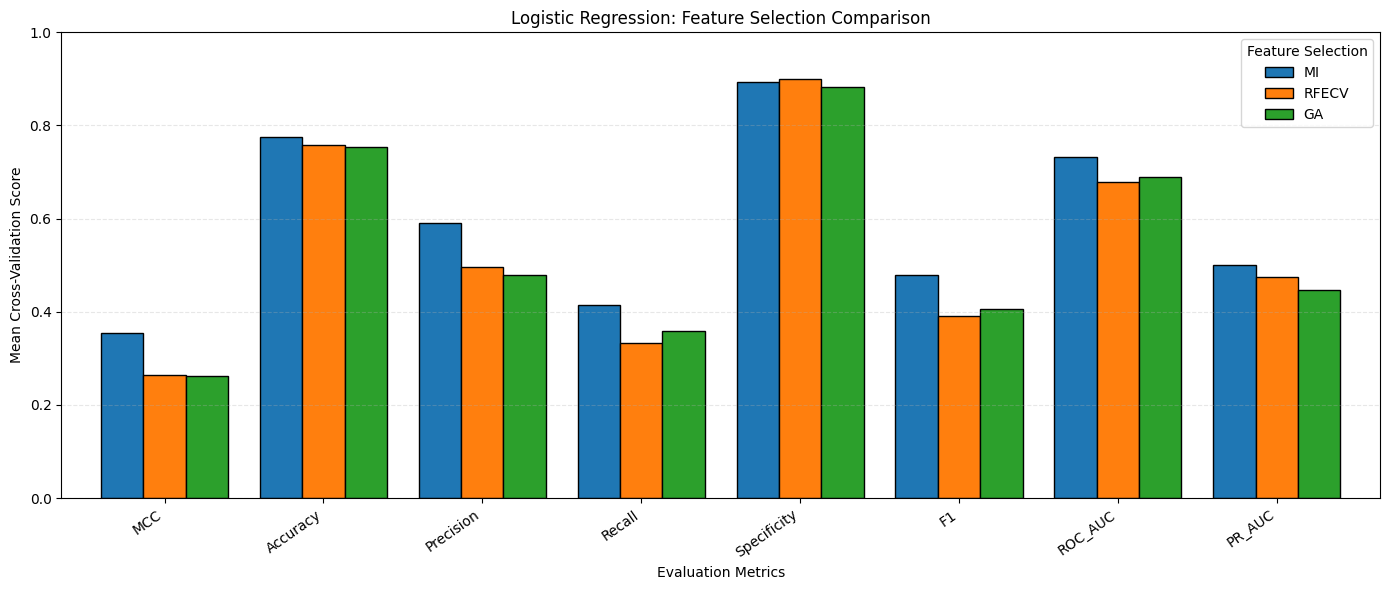

In [114]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["MCC", "Accuracy", "Precision", "Recall",
           "Specificity", "F1", "ROC_AUC", "PR_AUC"]

df = comparison_lr[metrics]

ax = df.T.plot(
    kind="bar",
    figsize=(14,6),
    width = 0.8,
    edgecolor = "black"
)

plt.title("Logistic Regression: Feature Selection Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Mean Cross-Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Feature Selection")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("LR_Feature_Selection_Performance.png", dpi=300)
plt.show()


In [115]:

# 4.2 Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

def Random_forest(X,y):
    
    # Stratified Cross validation
    cv_rf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state = 42
    )

    # Results
    results_rf = {
        "MI" : [],
        "RFECV" : [],
        "GA" : []
    }

    for train_idx , val_idx in cv_rf.split(X,y):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # 4.2.1 Random Forest Model
        model_rf = RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )

        # 4.2.2 Mutual Information for RF Model
        X_train_mi , mi_features,mi_selector = Mutual_info(X_train,y_train)
        X_val_mi_rf = X_val[mi_features]

        mi_model_rf = clone(model_rf)
        mi_model_rf.fit(X_train_mi,y_train)

        mi_pred_rf = mi_model_rf.predict(X_val_mi_rf)
        mi_prob_rf = mi_model_rf.predict_proba(X_val_mi_rf)[:,1]

        results_rf["MI"].append(
            evaluate_model(y_val,mi_pred_rf,mi_prob_rf)
        )
        
        # 4.2.3 RFECV for RF Model
        X_train_rfecv,selected_features_rfecv,rfecv = rfecv_selection(model_rf,X_train,y_train)

        X_val_rfecv_rf = X_val[selected_features_rfecv]

        rfecv_model_rf = clone(model_rf)
        rfecv_model_rf.fit(X_train_rfecv,y_train)

        rfecv_pred_rf = rfecv_model_rf.predict(X_val_rfecv_rf)
        rfecv_prob_rf = rfecv_model_rf.predict_proba(X_val_rfecv_rf)[:,1]

        results_rf["RFECV"].append(
            evaluate_model(y_val,rfecv_pred_rf,rfecv_prob_rf)
        )

        # 4.2.4 GA for RF Model
        X_train_ga,selected_feature_ga,selector_ga = genetic_selection(model_rf,X_train,y_train)

        X_val_ga_rf = X_val[selected_feature_ga]

        ga_model_rf = clone(model_rf)
        ga_model_rf.fit(X_train_ga,y_train)

        ga_pred_rf = ga_model_rf.predict(X_val_ga_rf)
        ga_prob_rf = ga_model_rf.predict_proba(X_val_ga_rf)[:,1]

        results_rf["GA"].append(
            evaluate_model(y_val,ga_pred_rf,ga_prob_rf)
        )
        
    return results_rf 

In [116]:
results_rf = Random_forest(X_train_processed,Ytrain)

Mutual Information selected 96 features
Recursive Feature selected 56 features
Selecting features with genetic algorithm.
gen	nevals	avg                               	std                               	min                            	max                                  
0  	10    	[  0.459452  72.2        0.058019]	[  0.093311  46.298596   0.021503]	[ 0.187587  2.        0.032316]	[   0.524907  138.          0.103573]
1  	6     	[  0.509369  59.3        0.047766]	[  0.022684  46.527519   0.013653]	[  0.452285  17.         0.037172]	[   0.524907  138.          0.0763  ]
2  	5     	[  0.507826  39.1        0.063069]	[  0.031582  41.534203   0.044745]	[  0.423852  17.         0.037172]	[   0.524907  138.          0.15943 ]
3  	3     	[  0.503556  19.7        0.054731]	[ 0.036007  4.290688  0.027699]   	[  0.416297  17.         0.037172]	[  0.524907  29.         0.108844]   
4  	6     	[  0.501027  19.2        0.060407]	[ 0.050466  2.712932  0.030581]   	[  0.357166  17.         0.037172

In [117]:
comparison_rf = pd.DataFrame({
    method: pd.DataFrame(scores).mean()
    for method, scores in results_rf.items()
}).T
print(comparison_rf)

            MCC  Accuracy  Precision    Recall  Specificity        F1  \
MI     0.492071  0.828092   0.938636  0.330435     0.991628  0.485616   
RFECV  0.463809  0.821820   0.868333  0.330797     0.983255  0.478758   
GA     0.442252  0.811338   0.807778  0.355797     0.960915  0.484531   

        ROC_AUC    PR_AUC  
MI     0.832447  0.727916  
RFECV  0.831604  0.709154  
GA     0.806364  0.684324  


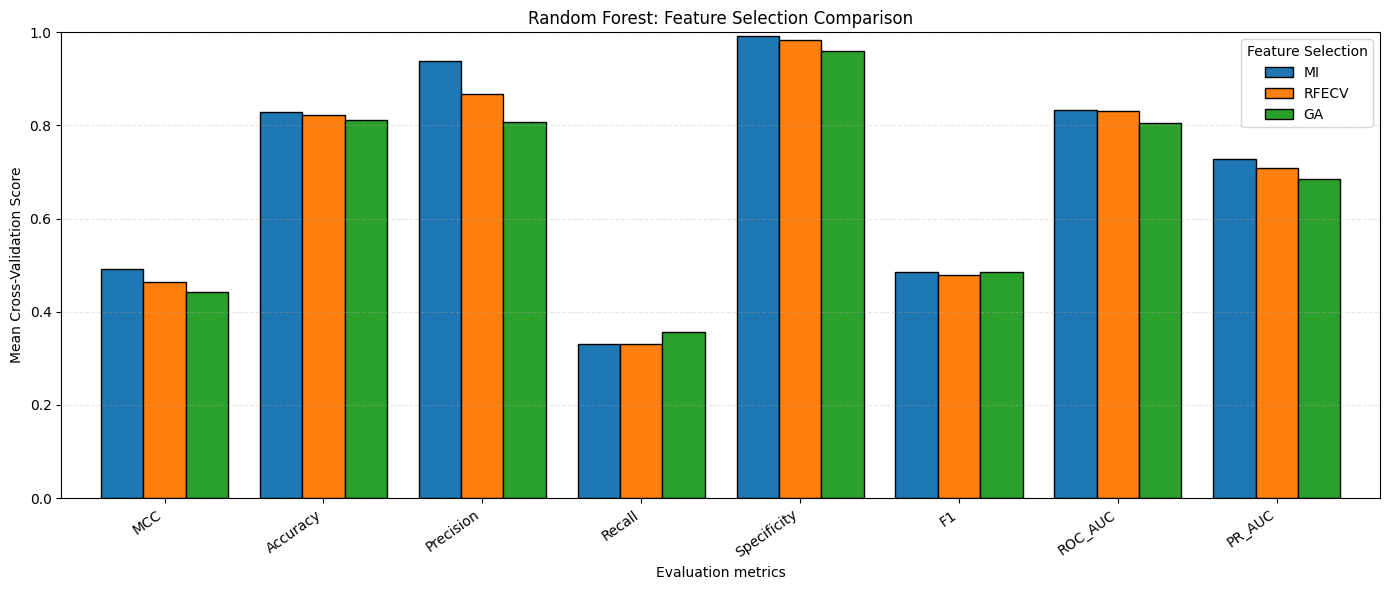

In [118]:
import matplotlib.pyplot as plt
import numpy as np

metrics = metrics = ["MCC", "Accuracy", "Precision", "Recall",
           "Specificity", "F1", "ROC_AUC", "PR_AUC"]

df = comparison_rf[metrics]

ax = df.T.plot(
    kind="bar",
    figsize=(14,6),
    width = 0.8,
    edgecolor = "black"
)

plt.title("Random Forest: Feature Selection Comparison")
plt.xlabel("Evaluation metrics")
plt.ylabel("Mean Cross-Validation Score")
plt.ylim(0,1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Feature Selection")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("RF_Feature_Selection_Performance.png", dpi=300)
plt.show()


In [119]:
# 4.3 Support Vector Machine

from sklearn.svm import SVC

def Support_vector_machine(X,y):

    # Stratified Cross validation
    cv_svm = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Results
    results_svm = {
        "MI": [],
        "RFECV": [],
        "GA": []
    }

    for train_idx, val_idx in cv_svm.split(X,y):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # 4.3.1 Support Vector Machine Model
        model_svm = SVC(
            kernel="linear",
            C=1.0,
            class_weight=None,
            probability=True,
            random_state=42
        )

        # 4.3.2 Mutual Information for SVM Model
        X_train_mi, mi_features, mi_selector = Mutual_info(X_train,y_train)
        X_val_mi_svm = X_val[mi_features]

        mi_model_svm = clone(model_svm)
        mi_model_svm.fit(X_train_mi,y_train)

        mi_pred_svm = mi_model_svm.predict(X_val_mi_svm)
        mi_prob_svm = mi_model_svm.predict_proba(X_val_mi_svm)[:,1]

        results_svm["MI"].append(
            evaluate_model(y_val,mi_pred_svm,mi_prob_svm)
        )

        # 4.3.3 RFECV for SVM Model
        X_train_rfecv,selected_features_rfecv,rfecv = rfecv_selection(
            model_svm,X_train,y_train
        )

        X_val_rfecv_svm = X_val[selected_features_rfecv]

        rfecv_model_svm = clone(model_svm)
        rfecv_model_svm.fit(X_train_rfecv,y_train)

        rfecv_pred_svm = rfecv_model_svm.predict(X_val_rfecv_svm)
        rfecv_prob_svm = rfecv_model_svm.predict_proba(X_val_rfecv_svm)[:,1]

        results_svm["RFECV"].append(
            evaluate_model(y_val,rfecv_pred_svm,rfecv_prob_svm)
        )

        # 4.3.4 GA for SVM Model
        X_train_ga,selected_feature_ga,selector_ga = genetic_selection(
            model_svm,X_train,y_train
        )

        X_val_ga_svm = X_val[selected_feature_ga]

        ga_model_svm = clone(model_svm)
        ga_model_svm.fit(X_train_ga,y_train)

        ga_pred_svm = ga_model_svm.predict(X_val_ga_svm)
        ga_prob_svm = ga_model_svm.predict_proba(X_val_ga_svm)[:,1]

        results_svm["GA"].append(
            evaluate_model(y_val,ga_pred_svm,ga_prob_svm)
        )

    return results_svm
    

In [120]:
results_svm = Support_vector_machine(X_train_processed,Ytrain)

Mutual Information selected 96 features
Recursive Feature selected 13 features
Selecting features with genetic algorithm.
gen	nevals	avg                               	std                               	min                            	max                                  
0  	10    	[  0.178624  64.2        0.063521]	[  0.14763   43.47827    0.042137]	[-0.013131  1.        0.      ]	[   0.337431  119.          0.146   ]
1  	6     	[   0.320653  105.8         0.093881]	[ 0.027931  7.586831  0.02901 ]   	[  0.260102  96.         0.065262]	[   0.348631  119.          0.175225]
2  	6     	[   0.346268  104.5         0.105822]	[ 0.024266  5.315073  0.037194]   	[  0.301078  97.         0.055191]	[   0.384235  114.          0.175225]
3  	7     	[   0.370505  101.6         0.0838  ]	[ 0.016633  3.666061  0.034364]   	[  0.342747  92.         0.035089]	[   0.388224  106.          0.141091]
4  	5     	[   0.348351  100.          0.101518]	[ 0.048855  3.794733  0.03157 ]   	[  0.233699  92.     

In [121]:

comparison_svm = pd.DataFrame({
    method: pd.DataFrame(scores).mean()
    for method, scores in results_svm.items()
}).T

print(comparison_svm.round(4))

print(comparison_svm)


          MCC  Accuracy  Precision  Recall  Specificity      F1  ROC_AUC  \
MI     0.3186    0.7633     0.5454  0.3989       0.8829  0.4572   0.7263   
RFECV  0.2793    0.7613     0.4702  0.3841       0.8858  0.4194   0.6838   
GA     0.3383    0.7675     0.5563  0.4246       0.8802  0.4743   0.6720   

       PR_AUC  
MI     0.5070  
RFECV  0.4882  
GA     0.4754  
            MCC  Accuracy  Precision    Recall  Specificity        F1  \
MI     0.318586  0.763289   0.545437  0.398913     0.882942  0.457170   
RFECV  0.279288  0.761272   0.470186  0.384058     0.885798  0.419356   
GA     0.338303  0.767500   0.556301  0.424638     0.880164  0.474318   

        ROC_AUC    PR_AUC  
MI     0.726295  0.507002  
RFECV  0.683818  0.488205  
GA     0.672030  0.475383  


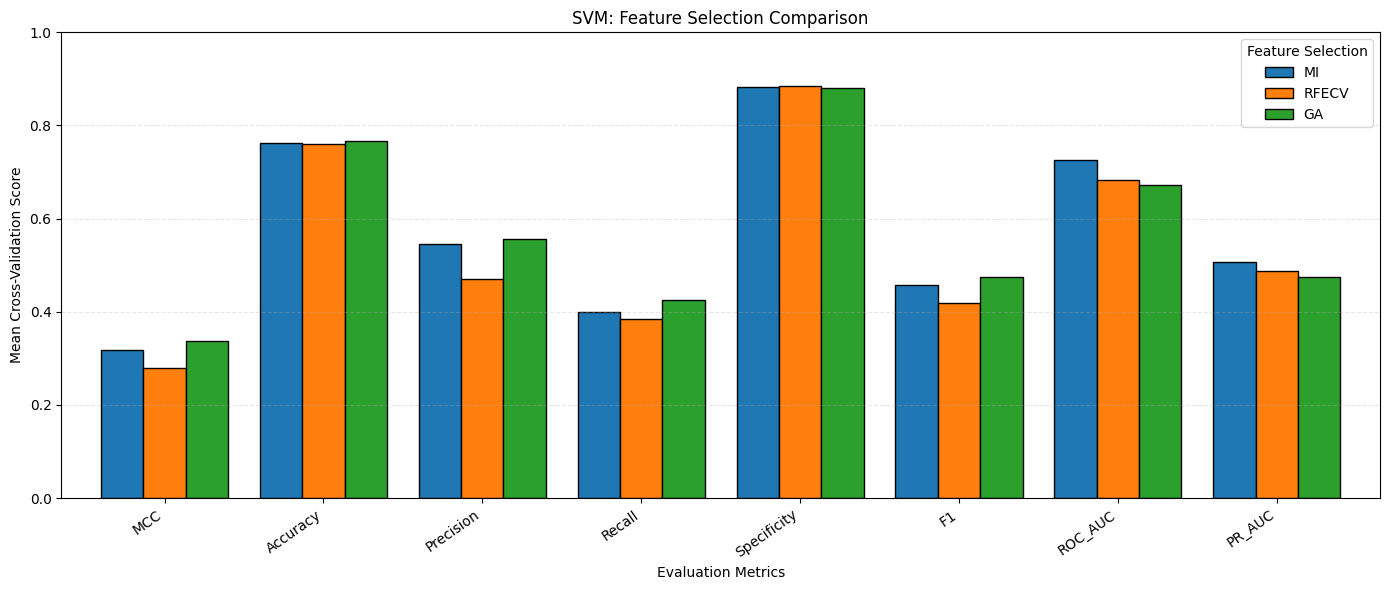

In [122]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["MCC", "Accuracy", "Precision", "Recall",
           "Specificity", "F1", "ROC_AUC", "PR_AUC"]

df = comparison_svm[metrics]

ax = df.T.plot(
    kind="bar",
    figsize=(14,6),
    width = 0.8,
    edgecolor = "black"
)

plt.title("SVM: Feature Selection Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Mean Cross-Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Feature Selection")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("SVM_Feature_Selection_Performance.png", dpi=300)
plt.show()


In [123]:
# 5. Class Imbalance Treatment Comparison and Evaluation
"""
5. Class Imbalance Treatment and Evaluation

We will use Random Forest with Mutual Information (MI) feature selection
to compare five different class imbalance strategies:

1. No Treatment (Baseline)
2. SMOTE
3. Class Weight
4. Random Oversampling
5. Random Undersampling

All strategies will be evaluated using stratified 5-fold cross-validation,
with imbalance treatments applied only to the training folds.

Model performance will be compared using MCC as the primary metric,
along with Accuracy, Precision, Recall, Specificity, F1-score,
ROC-AUC, and PR-AUC.

The best-performing imbalance strategy will be selected for
final model evaluation and SHAP-based interpretability analysis.
"""

'\n5. Class Imbalance Treatment and Evaluation\n\nWe will use Random Forest with Mutual Information (MI) feature selection\nto compare five different class imbalance strategies:\n\n1. No Treatment (Baseline)\n2. SMOTE\n3. Class Weight\n4. Random Oversampling\n5. Random Undersampling\n\nAll strategies will be evaluated using stratified 5-fold cross-validation,\nwith imbalance treatments applied only to the training folds.\n\nModel performance will be compared using MCC as the primary metric,\nalong with Accuracy, Precision, Recall, Specificity, F1-score,\nROC-AUC, and PR-AUC.\n\nThe best-performing imbalance strategy will be selected for\nfinal model evaluation and SHAP-based interpretability analysis.\n'

In [124]:
# 5.1 Random Forest - No Class Imbalance Treatment
from sklearn.ensemble import RandomForestClassifier


def RF_baseline(X_train, X_test,y_train):

    # Mutual Information Feature Selection
    X_train_mi , mi_features , mi_selector = Mutual_info(
        X_train,y_train
    )

    # Applying same selected feature to test data
    X_test_mi = X_test[mi_features]

    # Random Forest Model
    model_rf_baseline = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    )

    # Training Model
    model_rf_baseline.fit(X_train_mi,y_train)

    return model_rf_baseline,X_test_mi,mi_features


In [125]:
baseline_model , X_test_mi,mi_features= RF_baseline(
    X_train_processed,
    X_test_processed,
    Ytrain
)

Mutual Information selected 93 features


In [126]:
# 5.2 Model Evaluation

def evaluate_rf(model, X_test, y_test):

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluation Metrics
    results = evaluate_model(
        y_test,
        y_pred,
        y_prob
    )

    return results

In [127]:
baseline_results = evaluate_rf(
    baseline_model,
    X_test_mi,
    Ytest
)

print(baseline_results)

{'MCC': 0.5095670519306535, 'Accuracy': 0.8333333333333334, 'Precision': 0.8571428571428571, 'Recall': 0.4, 'Specificity': 0.9777777777777777, 'F1': 0.5454545454545455, 'ROC_AUC': 0.8805555555555555, 'PR_AUC': 0.740338148699141}


In [128]:
# 5.3 Model Evaluation Visulization

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

def plot_model_evaluation(model,X_test,y_test,model_name):

    # Predicitons
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    # Create Figure
    fig , axes = plt.subplots(2,2,figsize =(14,10))

    # Confusion Matrix
    cm = confusion_matrix(y_test,y_pred, labels=[0,1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["DIA Negative","DIA Positive"]
    ).plot(ax=axes[0,0],cmap="Blues", colorbar=False)

    axes[0,0].set_title("Confusion Matrix")

    # ROC Curve
    fpr , tpr , _ = roc_curve(y_test,y_prob)
    roc_auc = auc(fpr,tpr)

    axes[0,1].plot(
        fpr,tpr,
        label = f"AUC = {roc_auc:.3f}"
    )

    axes[0, 1].set_title("ROC Curve")
    axes[0, 1].set_xlabel("False Positive Rate")
    axes[0, 1].set_ylabel("True Positive Rate")
    axes[0, 1].legend()

    # Precision-Recall Curve
    # 5.3.4 Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(
        y_test, y_prob
    )

    pr_auc = average_precision_score(y_test, y_prob)

    axes[1, 0].plot(
        recall, precision,
        label=f"AP = {pr_auc:.3f}"
    )

    axes[1, 0].axhline(
        y=np.mean(y_test),
        linestyle="--",
        label="Positive Class Prevalence"
    )

    axes[1, 0].set_title("Precision-Recall Curve")
    axes[1, 0].set_xlabel("Recall")
    axes[1, 0].set_ylabel("Precision")
    axes[1, 0].legend()

    # 5.3.5 Predicted Probability Distribution
    axes[1, 1].hist(
        y_prob[np.asarray(y_test) == 0],
        bins=20,
        alpha=0.6,
        label="DIA Negative"
    )

    axes[1, 1].hist(
        y_prob[np.asarray(y_test) == 1],
        bins=20,
        alpha=0.6,
        label="DIA Positive"
    )

    axes[1, 1].axvline(
        0.5,
        linestyle="--",
        label="Threshold = 0.5"
    )

    axes[1, 1].set_title("Predicted Probability Distribution")
    axes[1, 1].set_xlabel("Predicted DIA-Positive Probability")
    axes[1, 1].set_ylabel("Number of Drugs")
    axes[1, 1].legend()

    # Figure Title
    fig.suptitle(
        f"{model_name} - Model Evaluation",
        fontsize=16
    )

    plt.tight_layout()

    # Save Figure
    filename = model_name.lower().replace(" ", "_")
    plt.savefig(
        f"{filename}_evaluation.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


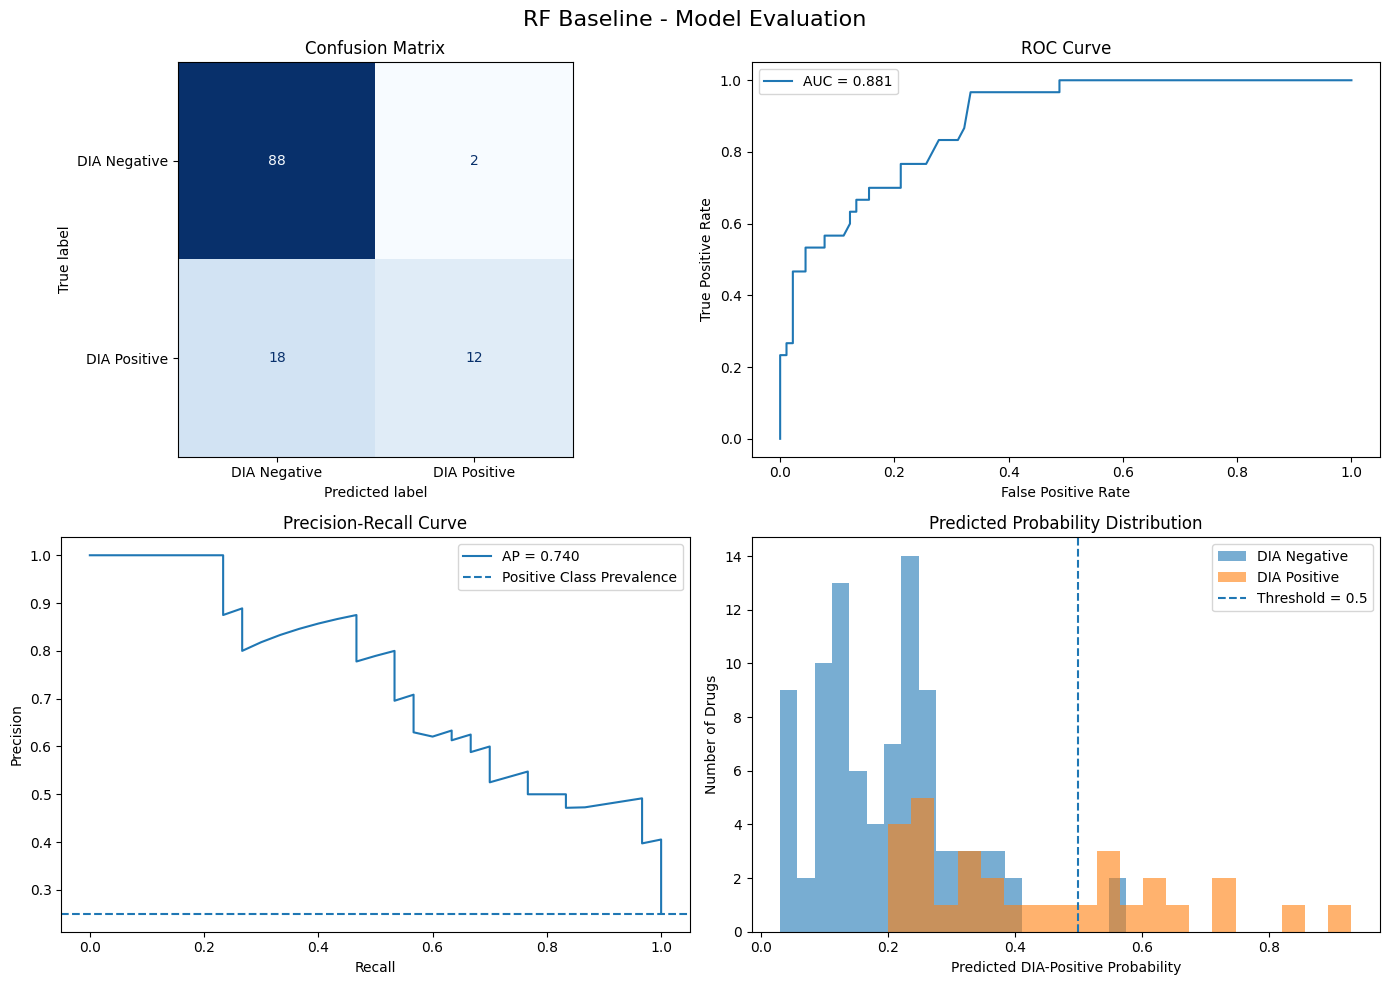

In [129]:
plot_model_evaluation(
    baseline_model,
    X_test_mi,
    Ytest,
    "RF Baseline"
)

In [130]:
from imblearn.over_sampling import SMOTE
# 6.1 Random Forest - SMOTE Treatment

def RF_SMOTE(X_train,X_test,y_train):
    
    # Mutual Information Feature Selection
    X_train_mi , mi_features , mi_selector = Mutual_info(
        X_train,y_train
    )

    # Applying same selected feature to test data
    X_test_mi = X_test[mi_features]

    # SMOTE Technique
    smote_rf = SMOTE(
        sampling_strategy="auto",
        k_neighbors=4,
        random_state=42
    )
    X_train_smote , y_train_smote = smote_rf.fit_resample(
        X_train_mi,y_train
    )

    # Random Forest Model
    model_rf_smote = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    )

    # Train using SMOTE-balanced data
    model_rf_smote.fit(X_train_smote,y_train_smote)

    return model_rf_smote,X_test_mi,mi_features



In [131]:
model_rf_smote , X_test_mi,mi_features = RF_SMOTE(
    X_train_processed,
    X_test_processed,
    Ytrain
)

Mutual Information selected 93 features


In [132]:
smote_results = evaluate_rf(
    model_rf_smote,
    X_test_mi,
    Ytest
)

print(smote_results)

{'MCC': 0.5418060522241288, 'Accuracy': 0.8416666666666667, 'Precision': 0.9230769230769231, 'Recall': 0.4, 'Specificity': 0.9888888888888889, 'F1': 0.5581395348837209, 'ROC_AUC': 0.8933333333333333, 'PR_AUC': 0.7936394702274938}


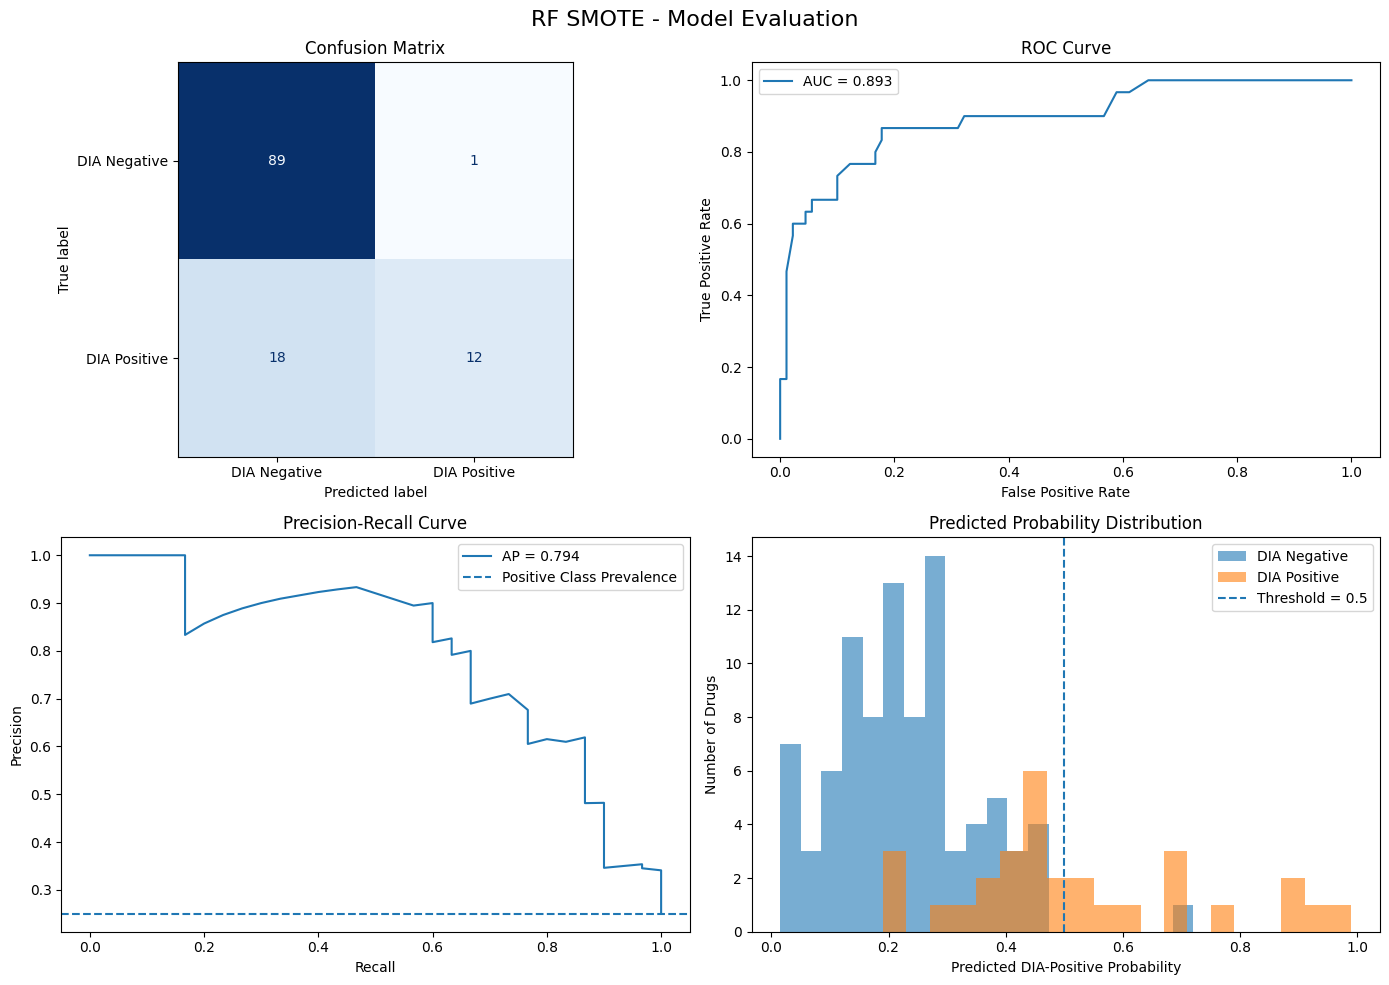

In [133]:
plot_model_evaluation(
    model_rf_smote,
    X_test_mi,
    Ytest,
    "RF SMOTE"
)

In [134]:
# 7.1 Random Forest - Class Weight

def RF_Class_weight(X_train,X_test,y_train):

    # Mutual Information Feature Selection
    X_train_mi , mi_features , mi_selector = Mutual_info(
        X_train,y_train
    )

    # Applying same selected feature to test data
    X_test_mi = X_test[mi_features]

    # Random Forest with class weight
    model_rf_weight = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight={0:1,1:5},
    random_state=42,
    n_jobs=-1
    )

    # Train Model 
    model_rf_weight.fit(X_train_mi,y_train)

    return model_rf_weight,X_test_mi,mi_features
    

In [135]:
model_rf_weight , X_test_mi,mi_features= RF_Class_weight(
    X_train_processed,
    X_test_processed,
    Ytrain
)

Mutual Information selected 93 features


In [136]:
weight_results = evaluate_rf(
    model_rf_weight,
    X_test_mi,
    Ytest
)

print(weight_results)

{'MCC': 0.48353484817774994, 'Accuracy': 0.825, 'Precision': 0.9090909090909091, 'Recall': 0.3333333333333333, 'Specificity': 0.9888888888888889, 'F1': 0.4878048780487804, 'ROC_AUC': 0.9014814814814816, 'PR_AUC': 0.7514805122167487}


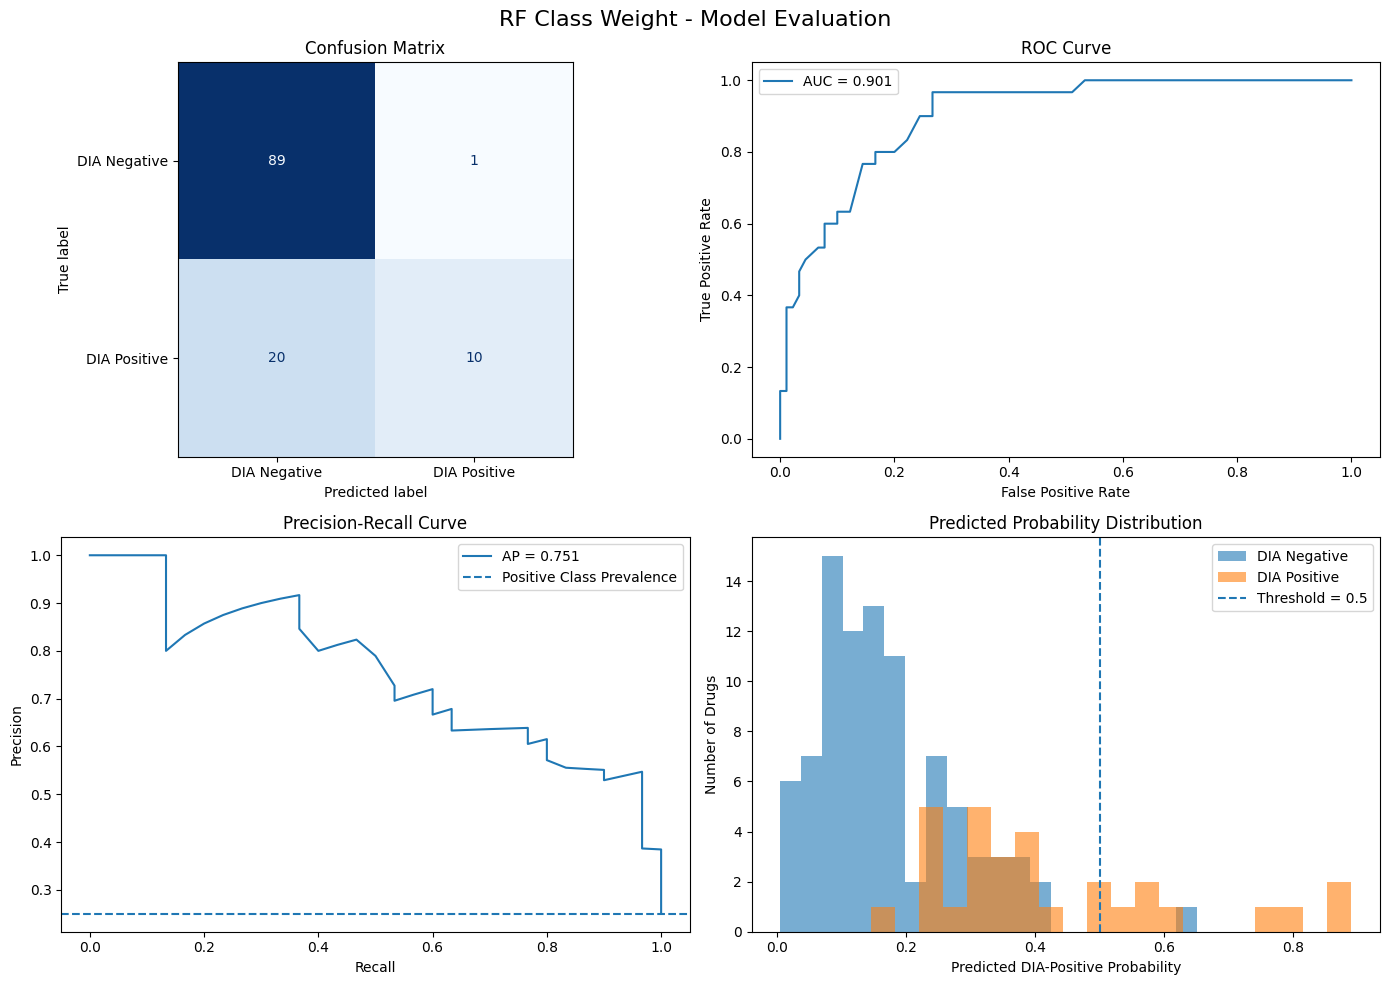

In [137]:
plot_model_evaluation(
    model_rf_weight,
    X_test_mi,
    Ytest,
    "RF Class Weight"
)

In [138]:
# 7.2 Random Forest - Random Oversampling (ROS)

from imblearn.over_sampling import RandomOverSampler

def RF_ROS(X_train,X_test,y_train):

    # Mutual Information Feature Selection
    X_train_mi , mi_features , mi_selector = Mutual_info(
        X_train,y_train
    )

    # Applying same selected feature to test data
    X_test_mi = X_test[mi_features]

    # Random Oversampling
    ros = RandomOverSampler(
        sampling_strategy="auto",
        random_state=42
    )

    # Applying ROS only on training data
    X_train_ros , y_train_ros = ros.fit_resample(
        X_train_mi,y_train
    )

    # Random Forest with Random Oversampling
    model_rf_ros = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    )

    # Train Model
    model_rf_ros.fit(X_train_ros,y_train_ros)

    return model_rf_ros,X_test_mi,mi_features

In [139]:
ros_model, X_test_ros, ros_features = RF_ROS(
    X_train_processed,
    X_test_processed,
    Ytrain
)

Mutual Information selected 93 features


In [140]:
ros_results = evaluate_rf(
    ros_model,
    X_test_ros,
    Ytest
)

print(ros_results)

{'MCC': 0.44961798699763555, 'Accuracy': 0.8166666666666667, 'Precision': 0.7857142857142857, 'Recall': 0.36666666666666664, 'Specificity': 0.9666666666666667, 'F1': 0.5, 'ROC_AUC': 0.885, 'PR_AUC': 0.7263758823008146}


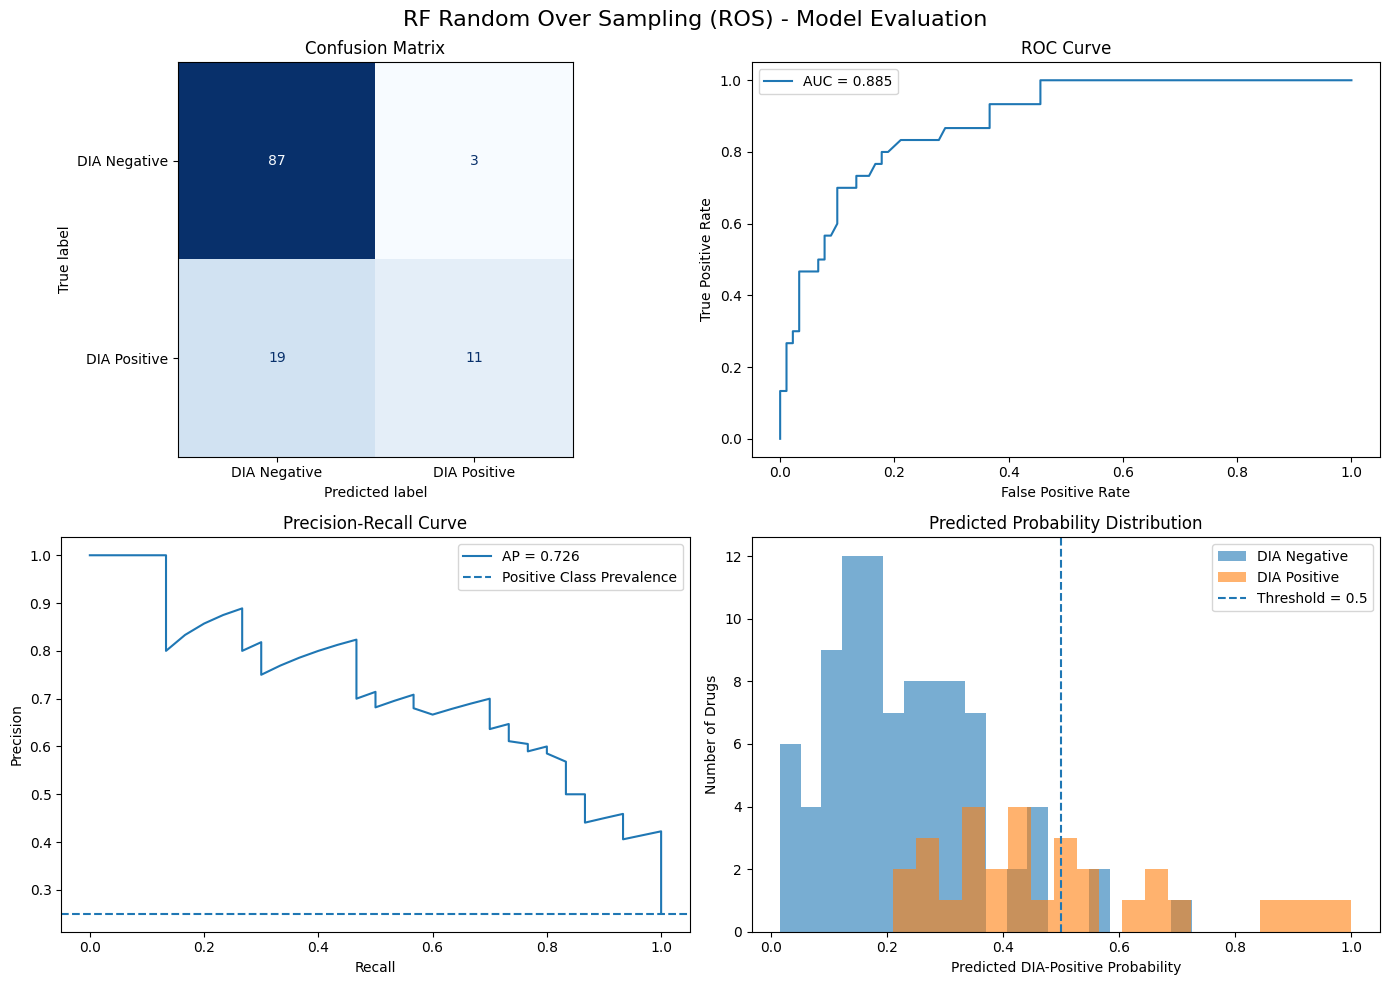

In [141]:
plot_model_evaluation(
    ros_model,
    X_test_mi,
    Ytest,
    "RF Random Over Sampling (ROS)"
)

In [142]:
# 7.3 Random Forest - Random Undersampling (RUS)

from imblearn.under_sampling import RandomUnderSampler

def RF_RUS(X_train,X_test,y_train):

    # Mutual Information Feature Selection
    X_train_mi , mi_features , mi_selector = Mutual_info(
        X_train,y_train
    )

    # Applying same selected feature to test data
    X_test_mi = X_test[mi_features]

    # Random Undersampling
    rus = RandomUnderSampler(
        sampling_strategy="auto",
        random_state=42
    )

    # Apply RUS only on training data
    X_train_rus , y_train_rus = rus.fit_resample(
        X_train_mi,y_train
    )

    # Random Forest with Random Undersampling
    model_rf_rus = RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    )

    # Train Model
    model_rf_rus.fit(X_train_rus,y_train_rus)

    return model_rf_rus,X_test_mi,mi_features

In [143]:
rus_model, X_test_rus, rus_features = RF_RUS(
    X_train_processed,
    X_test_processed,
    Ytrain
)


Mutual Information selected 93 features


In [144]:
rus_results = evaluate_rf(
    rus_model,
    X_test_mi,
    Ytest
)

print(rus_results)

{'MCC': 0.4600552765984855, 'Accuracy': 0.7416666666666667, 'Precision': 0.4897959183673469, 'Recall': 0.8, 'Specificity': 0.7222222222222222, 'F1': 0.6075949367088609, 'ROC_AUC': 0.8503703703703703, 'PR_AUC': 0.7185722814341444}


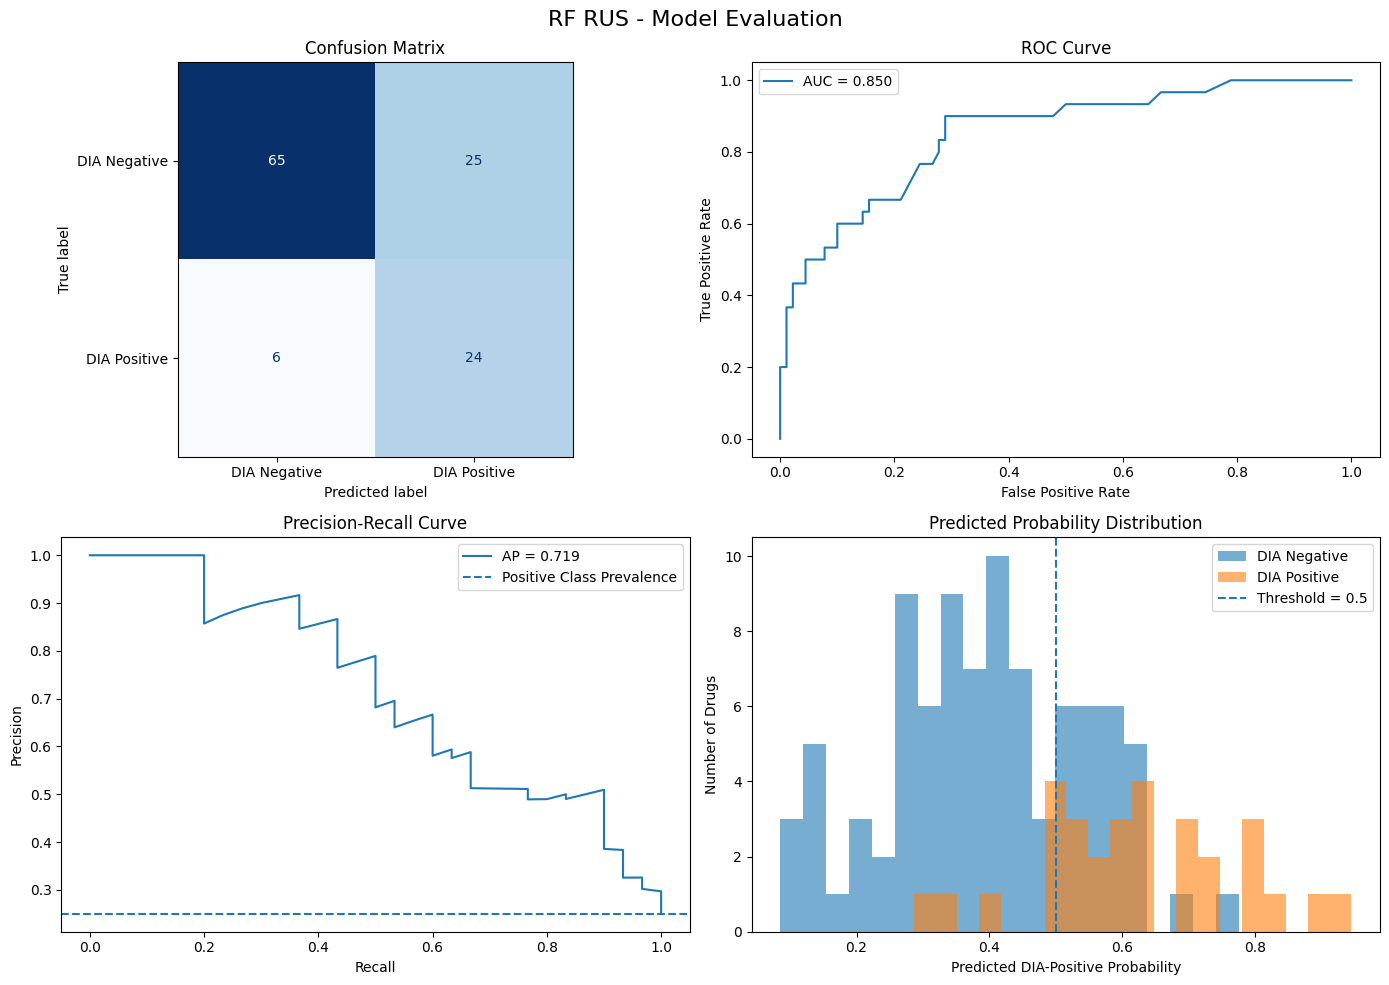

In [145]:
plot_model_evaluation(
    rus_model,
    X_test_rus,
    Ytest,
    "RF RUS"
)

In [146]:
# 8.1 SHAP Interpretability Analysis

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

def SHAP_analysis(model,X_test,model_name):

    # Create folder for SHAP plots
    os.makedirs("SHAP_Plots", exist_ok=True)

    # Create SHAP Explainer
    explainer = shap.TreeExplainer(model)

    # Calculate SHAP values
    shap_values = explainer(X_test)

    # Select DIA Positive Class(1)
    if shap_values.values.ndim == 3:
        shap_positive = shap_values[:,:,1]
    else:
        shap_positive = shap_values

    # Calculate Mean Absolute SHAP Values
    importance = np.abs(shap_positive.values).mean(axis=0)

    # Select Top 15 Features
    top_15_idx = np.argsort(importance)[-15:][::-1]
    shap_top15 = shap_positive[:,top_15_idx]

    # SHAP Beeswarm Plot
    shap.plots.beeswarm(
        shap_top15,
        max_display=16,
        show=False
    )

    plt.title(f"{model_name} - SHAP Beeswarm")
    plt.tight_layout()

    plt.savefig(
        f"SHAP_Plots/{model_name}_Beeswarm.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # SHAP Bar Plot
    shap.plots.bar(
        shap_top15,
        max_display=16,
        show=False
    )

    plt.title(f"{model_name} - SHAP Feature Importance")
    plt.tight_layout()

    plt.savefig(
        f"SHAP_Plots/{model_name}_Bar.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # Store All Feature Importance Values
    shap_importance = pd.DataFrame({
        "Feature": X_test.columns,
        "Mean_SHAP": importance
    }).sort_values(
        by="Mean_SHAP",
        ascending=False
    )

    return shap_importance





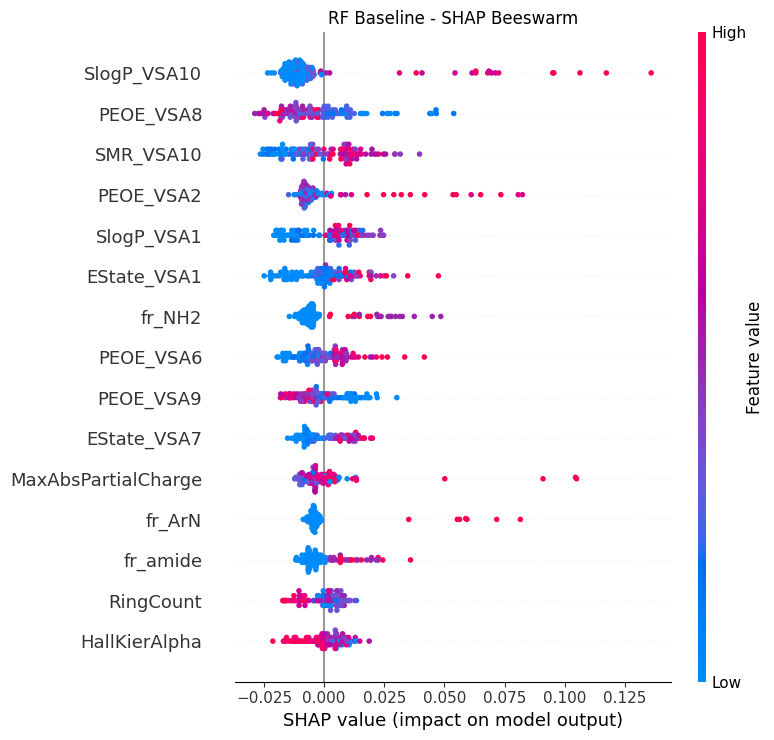

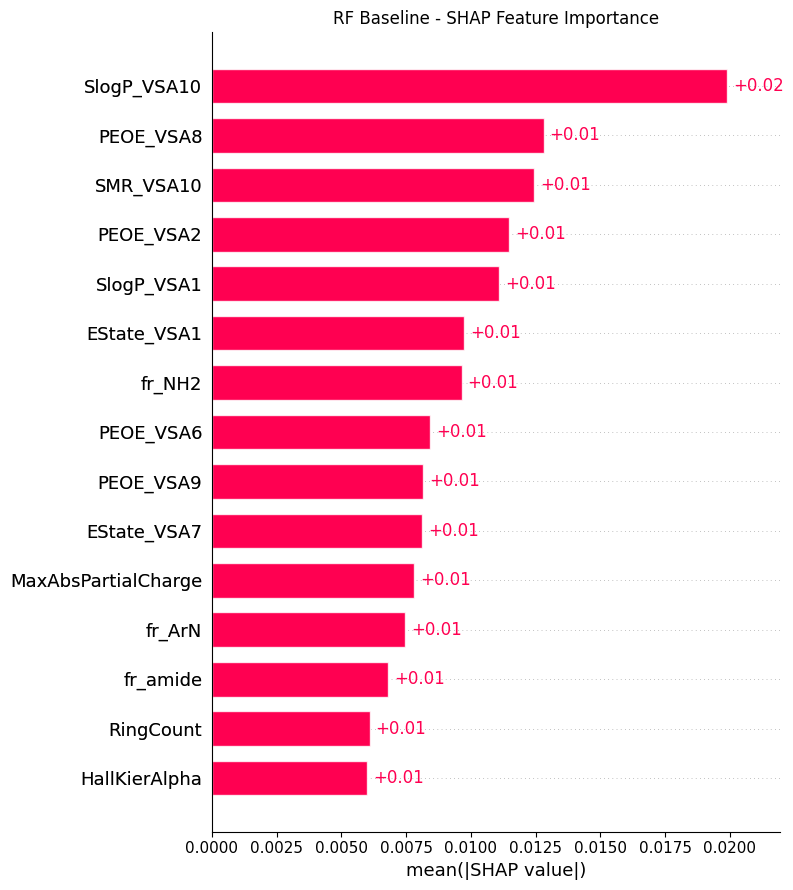

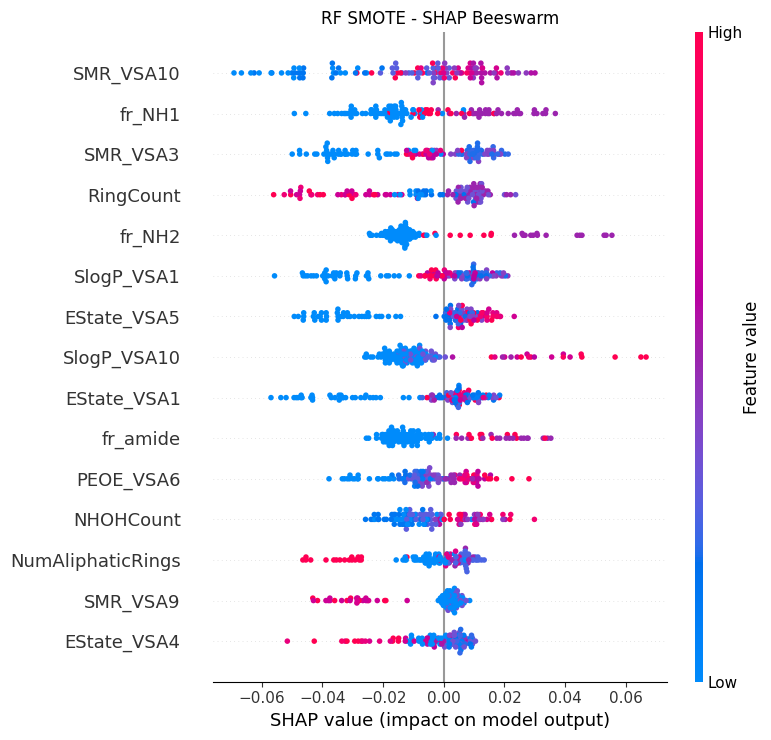

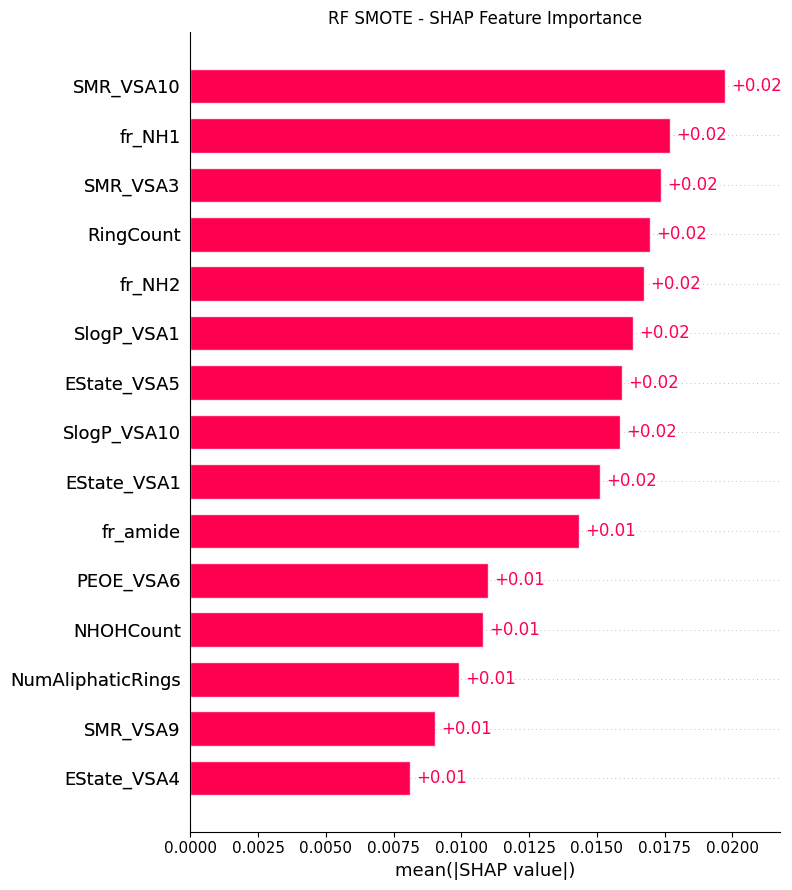

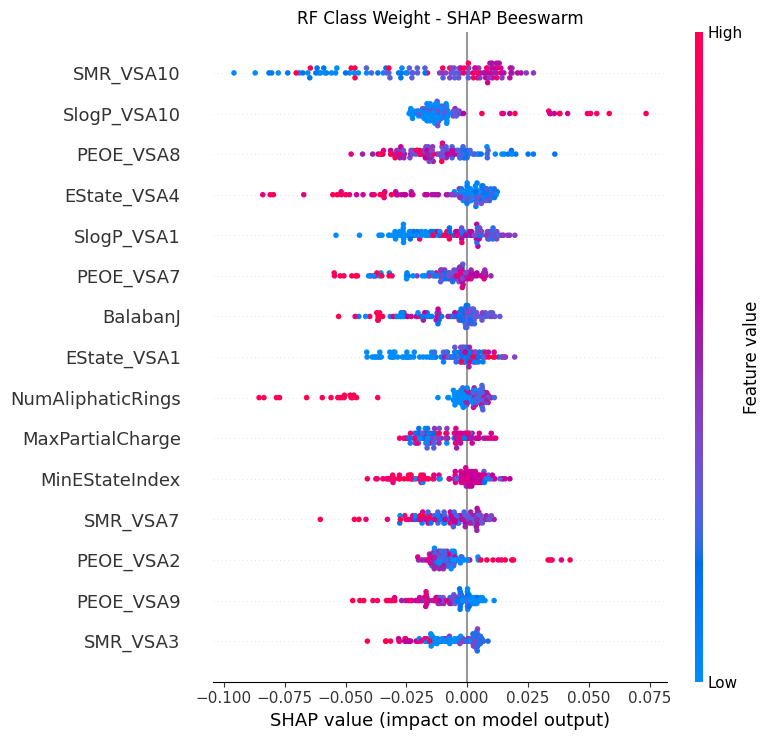

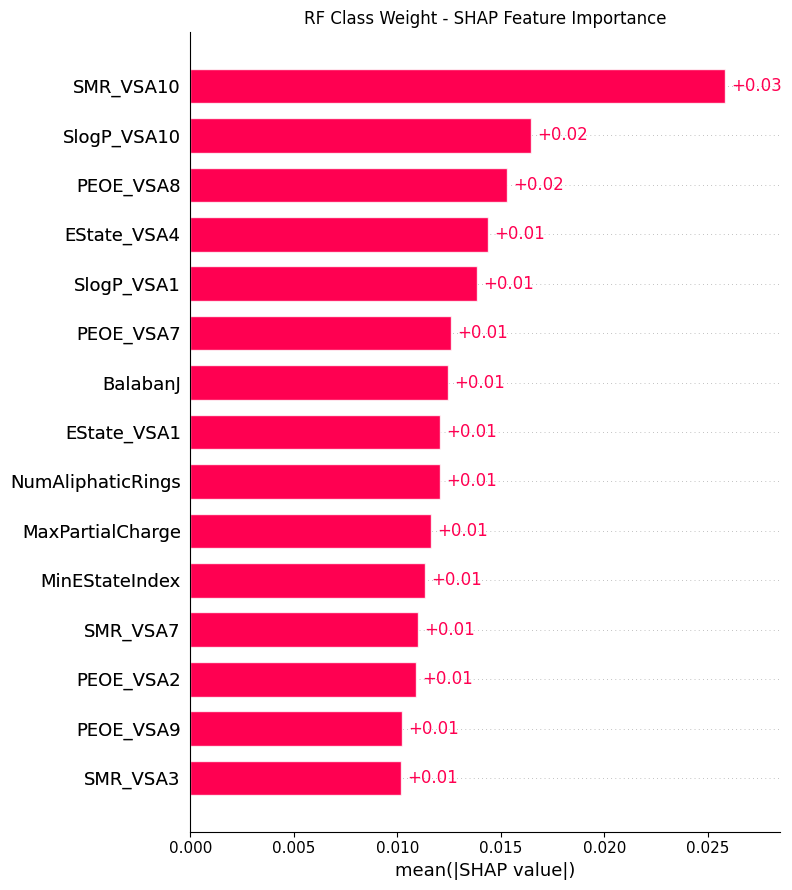

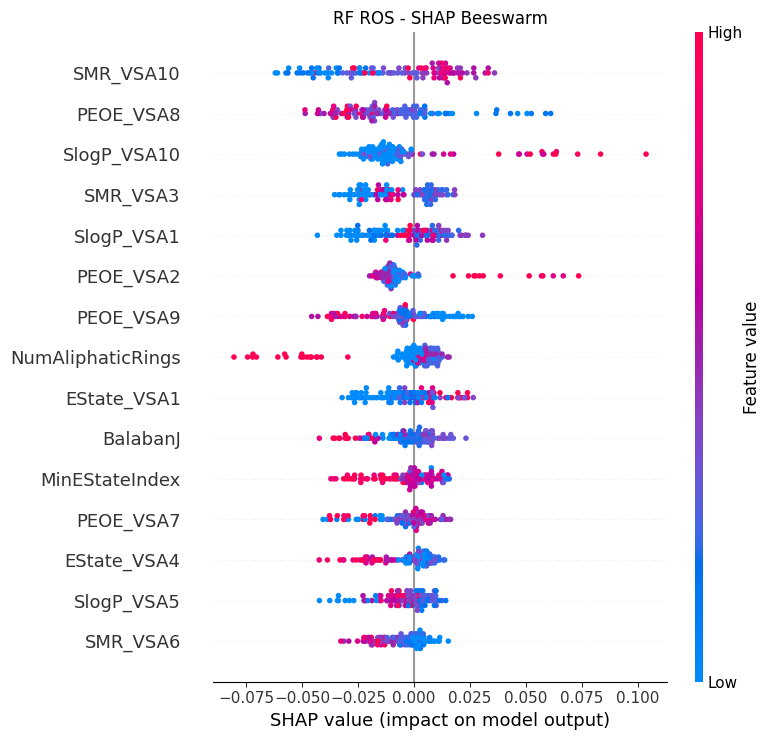

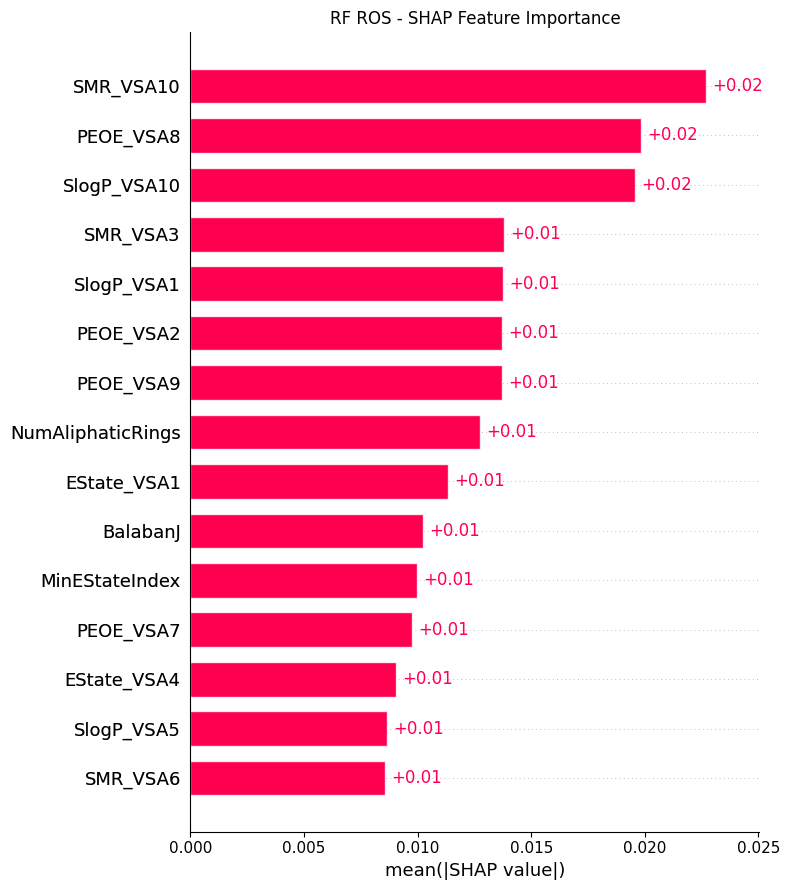

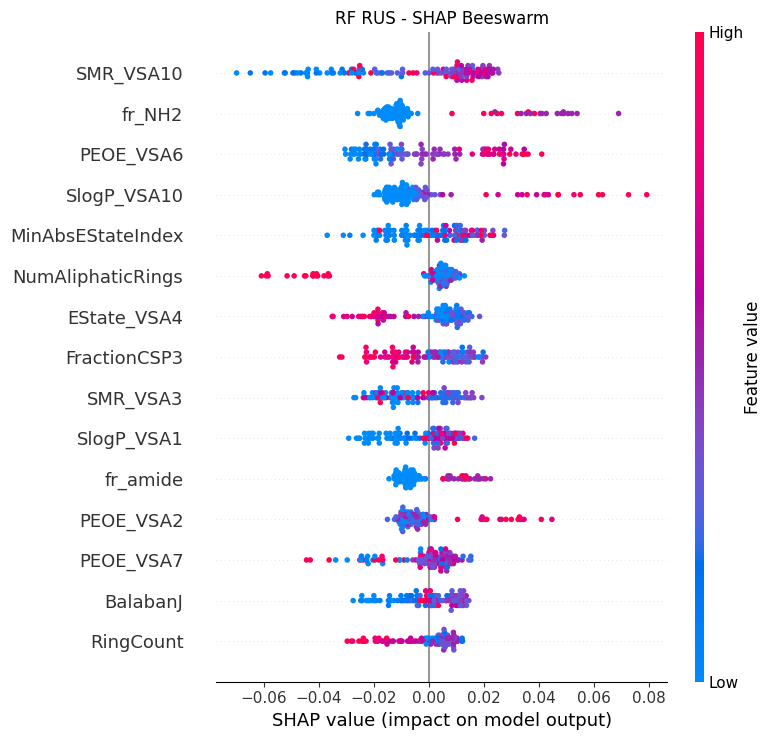

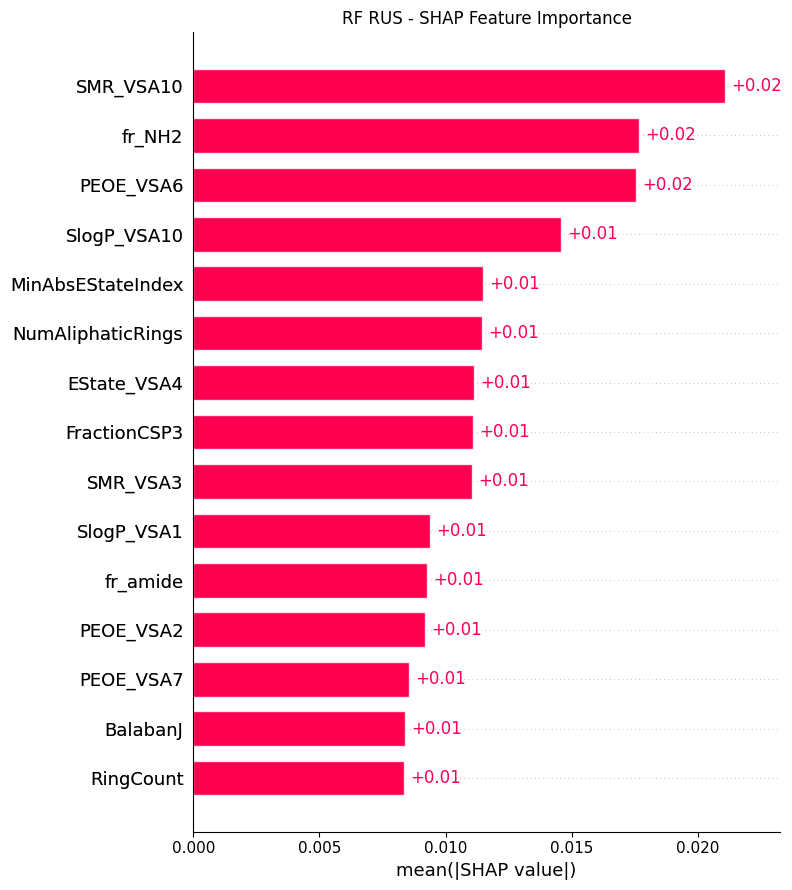

In [147]:
# Baseline
shap_baseline = SHAP_analysis(
    baseline_model,
    X_test_mi,
    "RF Baseline"
)

# SMOTE
shap_smote = SHAP_analysis(
    model_rf_smote,
    X_test_mi,
    "RF SMOTE"
)

# Class Weight
shap_weight = SHAP_analysis(
    model_rf_weight,
    X_test_mi,
    "RF Class Weight"
)

# ROS
shap_ros = SHAP_analysis(
    ros_model,
    X_test_mi,
    "RF ROS"
)

# RUS
shap_rus = SHAP_analysis(
    rus_model,
    X_test_mi,
    "RF RUS"
)

In [148]:
# Comparing the Shap Feature Ranking

# Rename the importance columns
shap_baseline = shap_baseline.rename(
    columns={"Mean_SHAP": "Baseline"}
)

shap_smote = shap_smote.rename(
    columns={"Mean_SHAP": "SMOTE"}
)

shap_weight = shap_weight.rename(
    columns={"Mean_SHAP": "Class Weight"}
)

shap_ros = shap_ros.rename(
    columns={"Mean_SHAP": "ROS"}
)

shap_rus = shap_rus.rename(
    columns={"Mean_SHAP": "RUS"}
)

# Combine by feature name
shap_comparison = (
    shap_baseline
    .merge(shap_smote, on="Feature")
    .merge(shap_weight, on="Feature")
    .merge(shap_ros, on="Feature")
    .merge(shap_rus, on="Feature")
)

print(shap_comparison.head(15))

                Feature  Baseline     SMOTE  Class Weight       ROS       RUS
0           SlogP_VSA10  0.019895  0.015868      0.016442  0.019585  0.014554
1             PEOE_VSA8  0.012809  0.007894      0.015295  0.019850  0.006783
2             SMR_VSA10  0.012438  0.019740      0.025847  0.022711  0.021082
3             PEOE_VSA2  0.011463  0.006004      0.010882  0.013722  0.009199
4            SlogP_VSA1  0.011078  0.016326      0.013867  0.013769  0.009372
5           EState_VSA1  0.009730  0.015133      0.012065  0.011324  0.006979
6                fr_NH2  0.009642  0.016753      0.007736  0.008438  0.017641
7             PEOE_VSA6  0.008429  0.010993      0.007979  0.008179  0.017553
8             PEOE_VSA9  0.008162  0.005717      0.010232  0.013704  0.007370
9           EState_VSA7  0.008122  0.007161      0.005590  0.004281  0.006922
10  MaxAbsPartialCharge  0.007802  0.004154      0.006071  0.004807  0.004105
11               fr_ArN  0.007447  0.005398      0.003767  0.005

In [149]:
# Calculate Spearman correlation

methods = [
    "Baseline",
    "SMOTE",
    "Class Weight",
    "ROS",
    "RUS"
]

spearman_corr = shap_comparison[methods].corr(
    method="spearman"
)

print(spearman_corr.round(3))

              Baseline  SMOTE  Class Weight    ROS    RUS
Baseline         1.000  0.822         0.845  0.871  0.852
SMOTE            0.822  1.000         0.817  0.838  0.799
Class Weight     0.845  0.817         1.000  0.951  0.886
ROS              0.871  0.838         0.951  1.000  0.886
RUS              0.852  0.799         0.886  0.886  1.000


In [150]:
# Get top 10 features for one strategy
def get_top10(df, method):
    return set(
        df.nlargest(10, method)["Feature"]
    )

# Compare top-10 features
overlap = pd.DataFrame(index=methods, columns=methods)

for method1 in methods:
    for method2 in methods:

        top1 = get_top10(shap_comparison, method1)
        top2 = get_top10(shap_comparison, method2)

        overlap.loc[method1, method2] = len(top1 & top2)

print(overlap)

             Baseline SMOTE Class Weight ROS RUS
Baseline           10     5            5   7   5
SMOTE               5    10            4   5   5
Class Weight        5     4           10   7   5
ROS                 7     5            7  10   5
RUS                 5     5            5   5  10


In [151]:
# Count how often each feature appears in the top 10
feature_counts = {}

for method in methods:

    top10 = get_top10(shap_comparison, method)

    for feature in top10:
        feature_counts[feature] = feature_counts.get(feature, 0) + 1

# Convert to DataFrame
stable_features = pd.DataFrame(
    feature_counts.items(),
    columns=["Feature", "Top10_Frequency"]
)

stable_features = stable_features.sort_values(
    by="Top10_Frequency",
    ascending=False
)

print(stable_features)

              Feature  Top10_Frequency
0         SlogP_VSA10                5
4          SlogP_VSA1                5
8           SMR_VSA10                5
6         EState_VSA1                4
5              fr_NH2                3
10           SMR_VSA3                3
1           PEOE_VSA8                3
17  NumAliphaticRings                3
2           PEOE_VSA2                2
3           PEOE_VSA9                2
9           PEOE_VSA6                2
19        EState_VSA4                2
15           BalabanJ                2
16   MaxPartialCharge                1
20       FractionCSP3                1
18          PEOE_VSA7                1
11        EState_VSA5                1
14          RingCount                1
13             fr_NH1                1
12           fr_amide                1
7         EState_VSA7                1
21  MinAbsEStateIndex                1


In [152]:
# 8.2 SHAP Dependence Plot Analysis

import shap
import matplotlib.pyplot as plt
import os

def SHAP_dependence(model, X_test, model_name):

    # Create folder
    os.makedirs("SHAP_Plots/Dependence", exist_ok=True)

    # Important features
    features = [
        "SlogP_VSA10",
        "SlogP_VSA1",
        "SMR_VSA10"
    ]

    # Create SHAP Explainer
    explainer = shap.TreeExplainer(model)

    # Calculate SHAP values
    shap_values = explainer(X_test)

    # Select DIA-positive class (1)
    if shap_values.values.ndim == 3:
        shap_positive = shap_values[:, :, 1]
    else:
        shap_positive = shap_values

    # Generate dependence plot for each feature
    for feature in features:

        shap.plots.scatter(
            shap_positive[:, feature],
            show=False
        )

        plt.title(f"{model_name} - {feature}")
        plt.tight_layout()

        # Save plot
        plt.savefig(
            f"SHAP_Plots/Dependence/{model_name}_{feature}.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

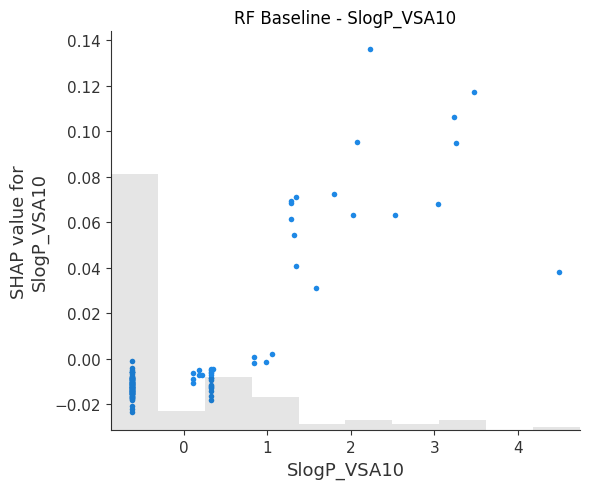

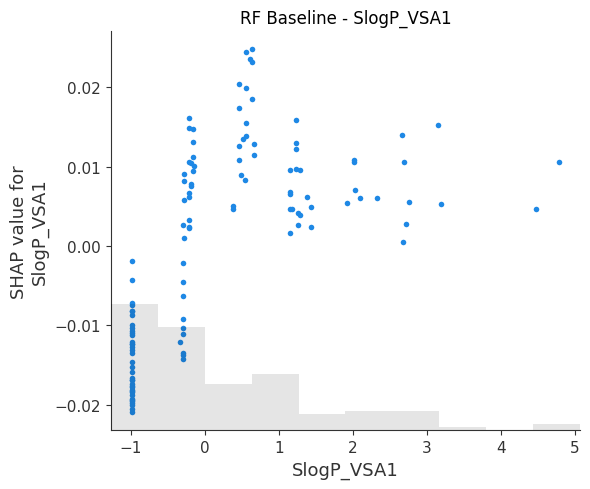

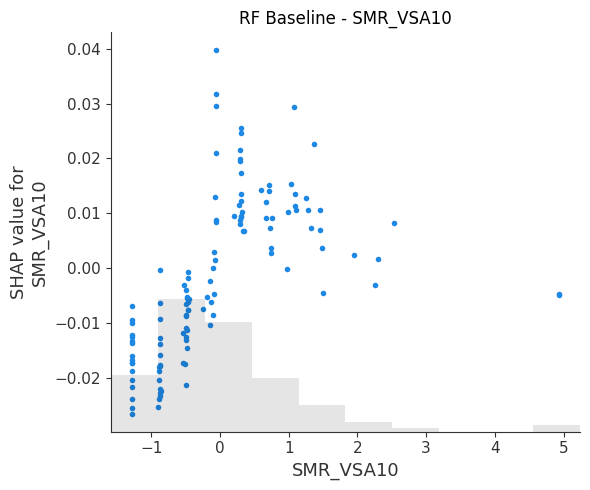

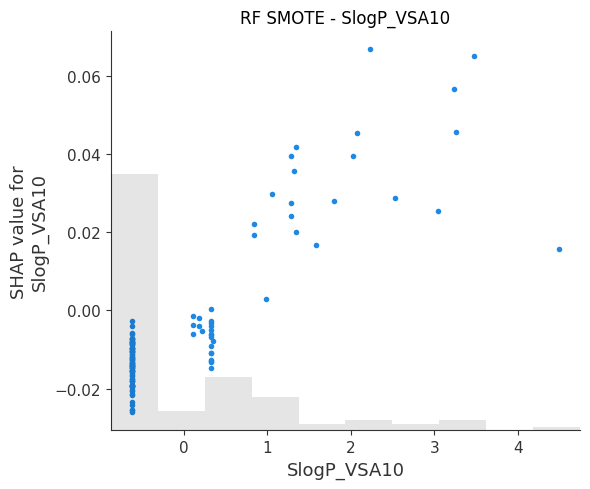

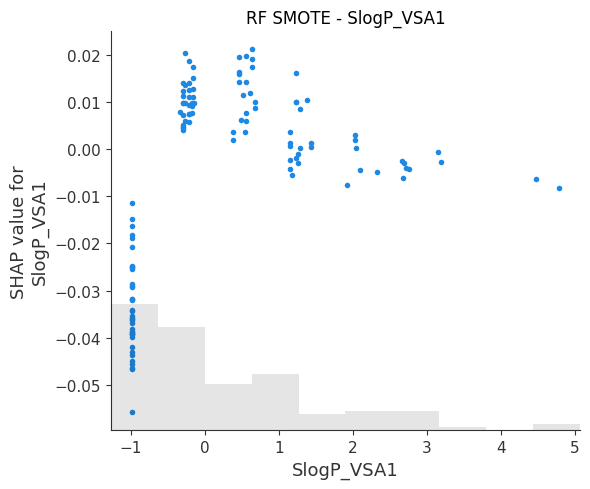

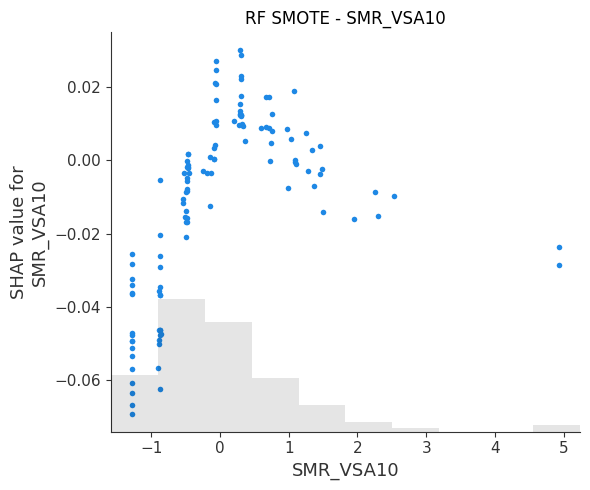

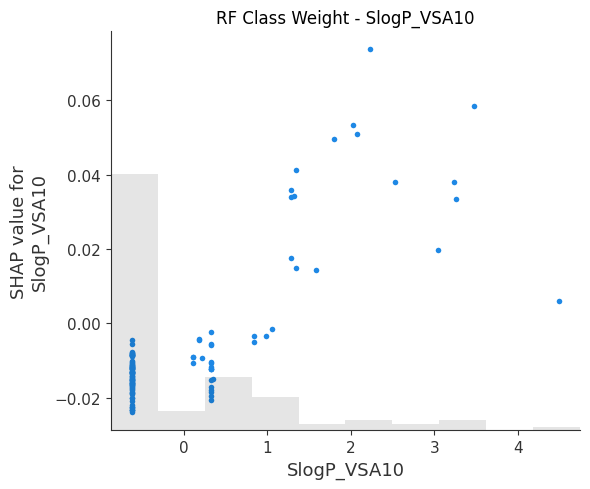

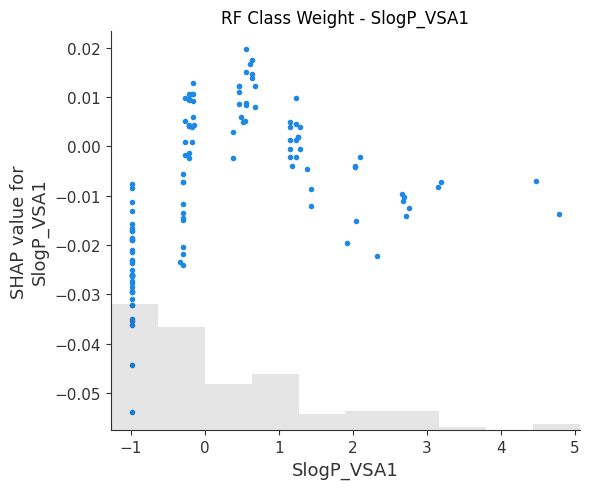

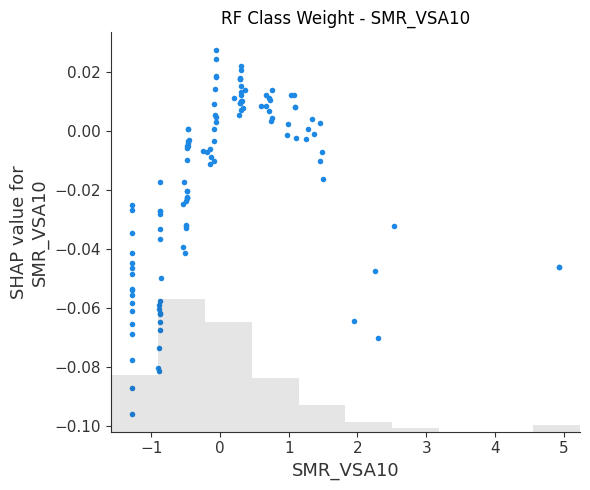

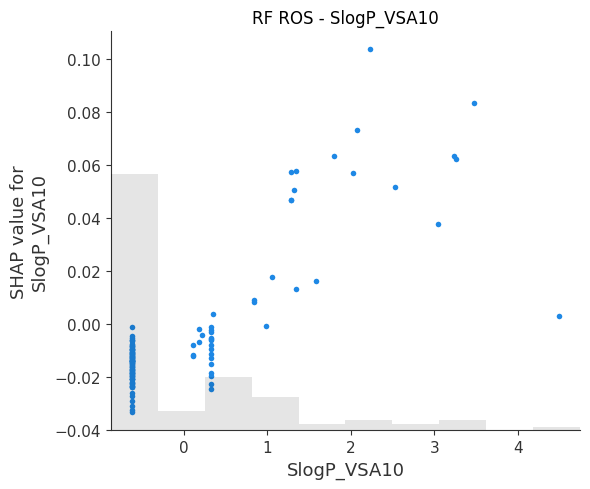

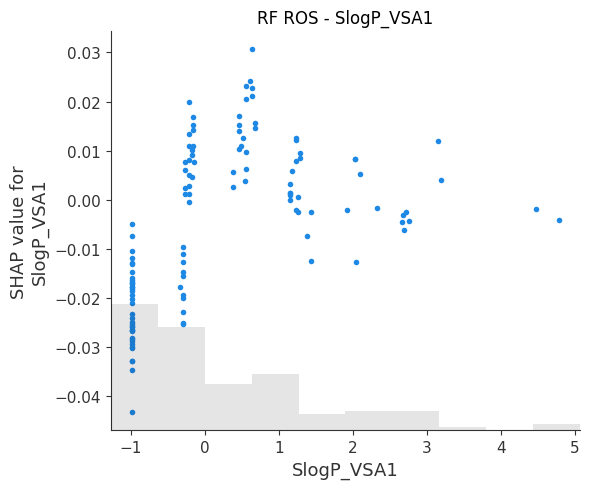

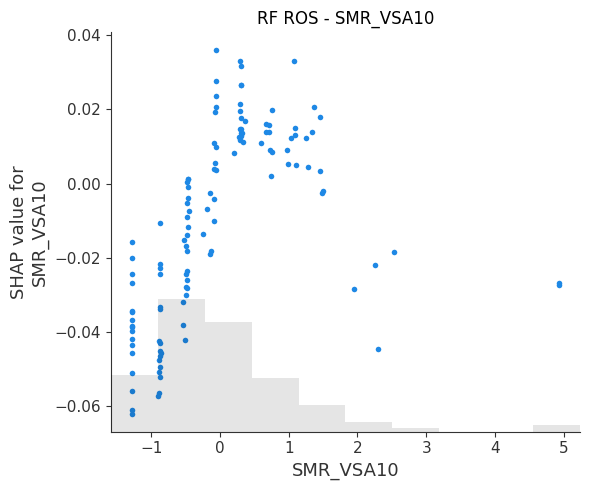

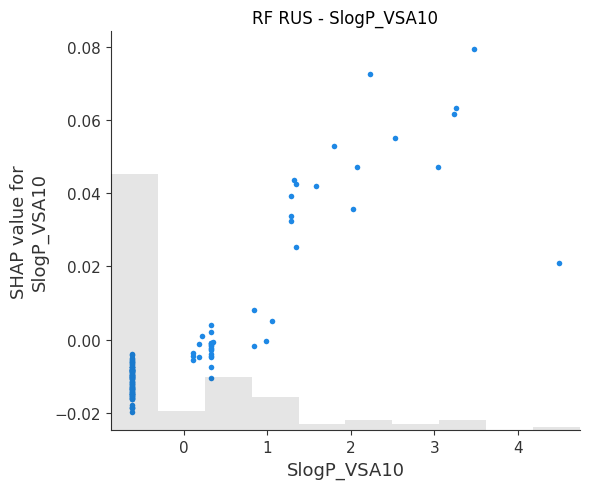

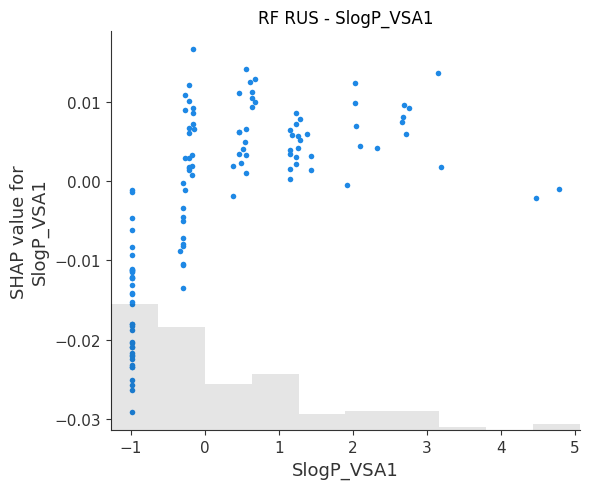

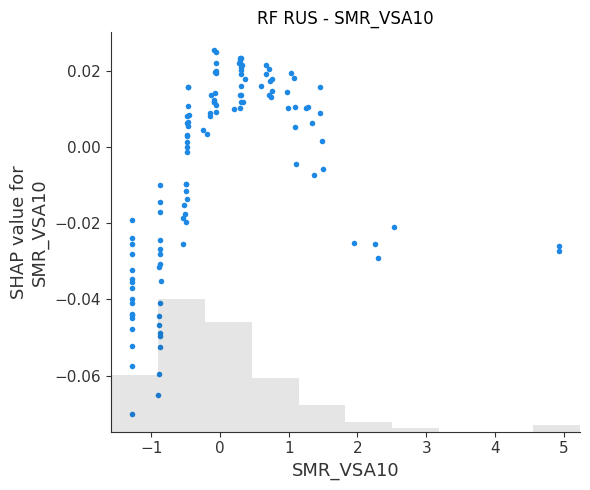

In [153]:
# Baseline
SHAP_dependence(
    baseline_model,
    X_test_mi,
    "RF Baseline"
)

# SMOTE
SHAP_dependence(
    model_rf_smote,
    X_test_mi,
    "RF SMOTE"
)

# Class Weight
SHAP_dependence(
    model_rf_weight,
    X_test_mi,
    "RF Class Weight"
)

# ROS
SHAP_dependence(
    ros_model,
    X_test_mi,
    "RF ROS"
)

# RUS
SHAP_dependence(
    rus_model,
    X_test_mi,
    "RF RUS"
)

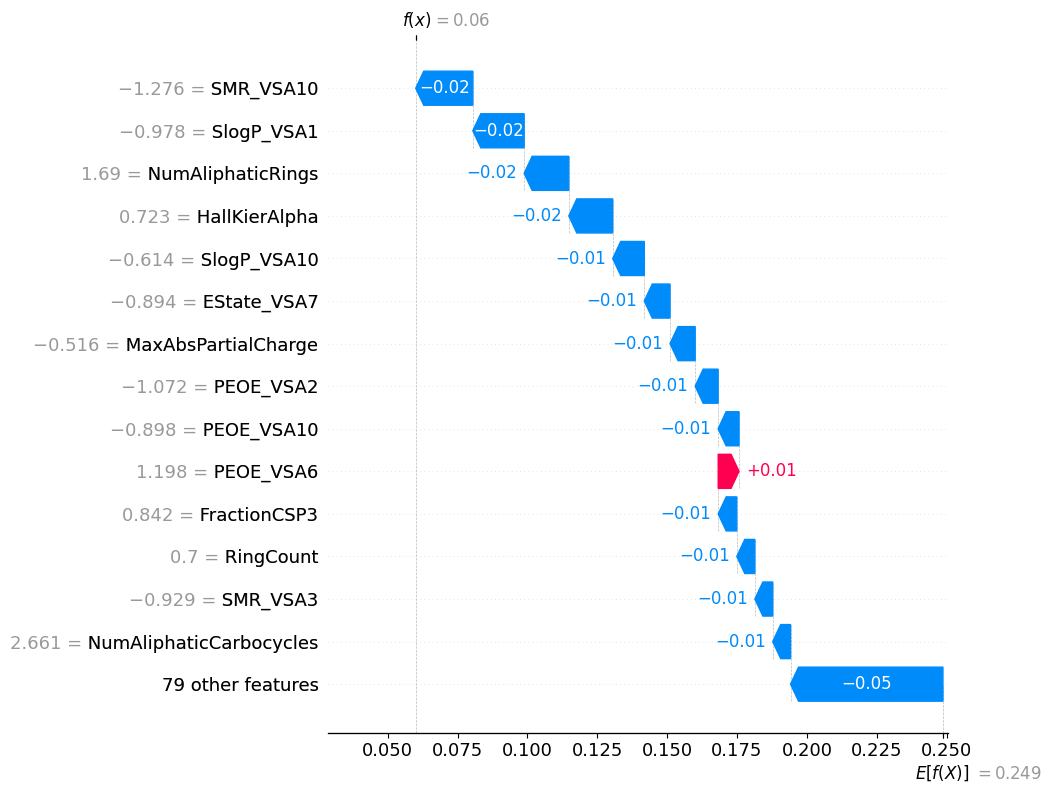

In [154]:
# 8.3 SHAP Waterfall Plot

explainer = shap.TreeExplainer(baseline_model)

shap_values = explainer(X_test_mi)

# Select DIA-positive class
if shap_values.values.ndim == 3:
    shap_positive = shap_values[:, :, 1]
else:
    shap_positive = shap_values

# Explain the first drug in the test dataset
shap.plots.waterfall(
    shap_positive[0],
    max_display=15
)

In [155]:
# Expected prediction for DIA-positive
print("Base value:", shap_positive[0].base_values)

# Sum of all SHAP contributions
print("Total SHAP:", shap_positive[0].values.sum())

# Final model prediction
print("SHAP prediction:",
      shap_positive[0].base_values
      + shap_positive[0].values.sum())

# Verify against Random Forest
print("RF probability:",
      baseline_model.predict_proba(X_test_mi.iloc[[0]])[0, 1])

Base value: 0.24870020964360598
Total SHAP: -0.18870020964360598
SHAP prediction: 0.06
RF probability: 0.06



Baseline
Base value: 0.2487
Total SHAP: -0.1887
Prediction: 0.0600


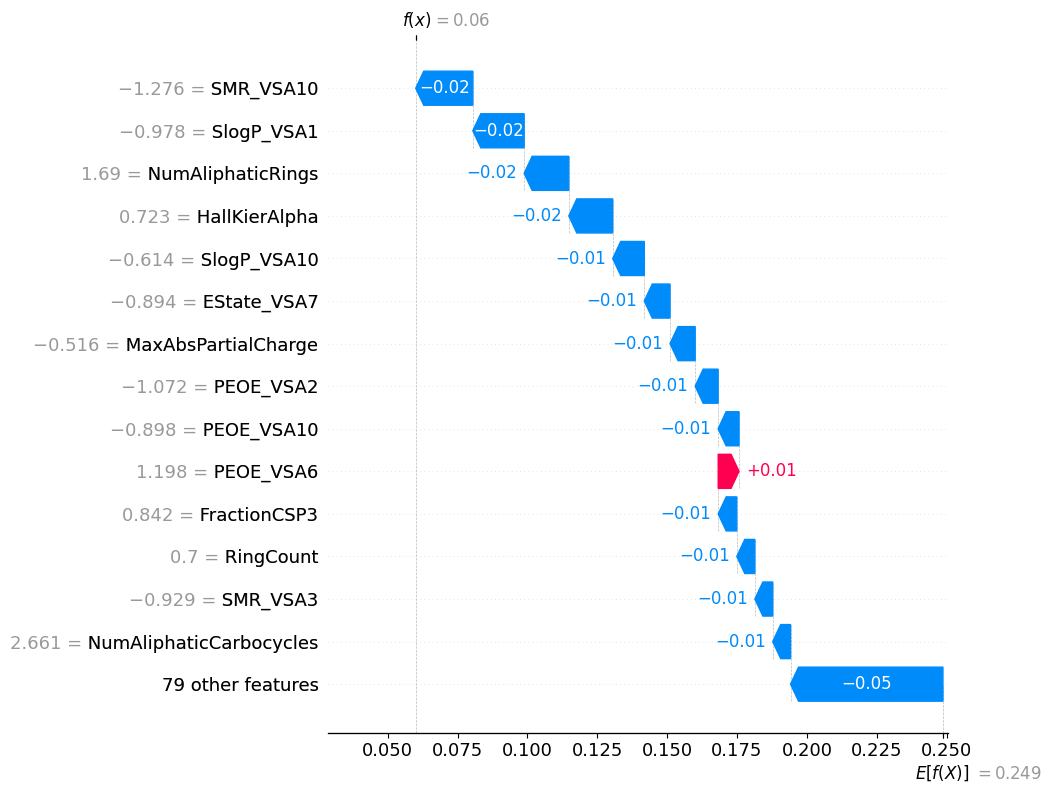


SMOTE
Base value: 0.5024
Total SHAP: -0.3924
Prediction: 0.1100


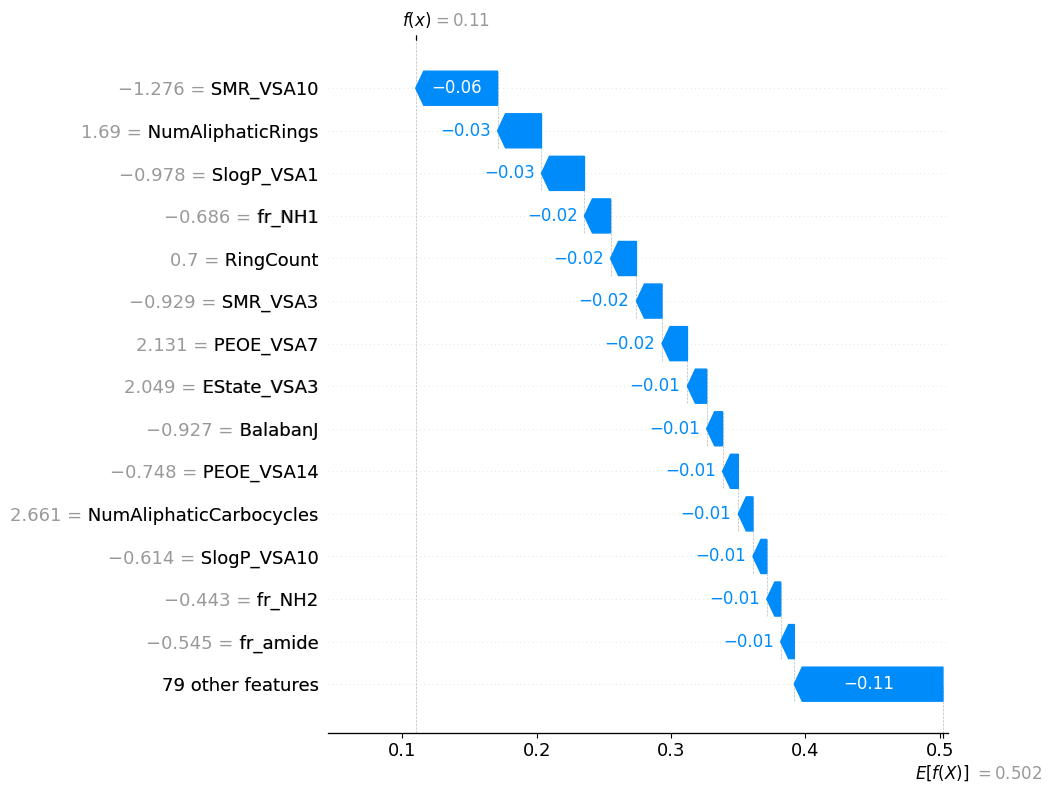


Class Weight
Base value: 0.6224
Total SHAP: -0.5724
Prediction: 0.0500


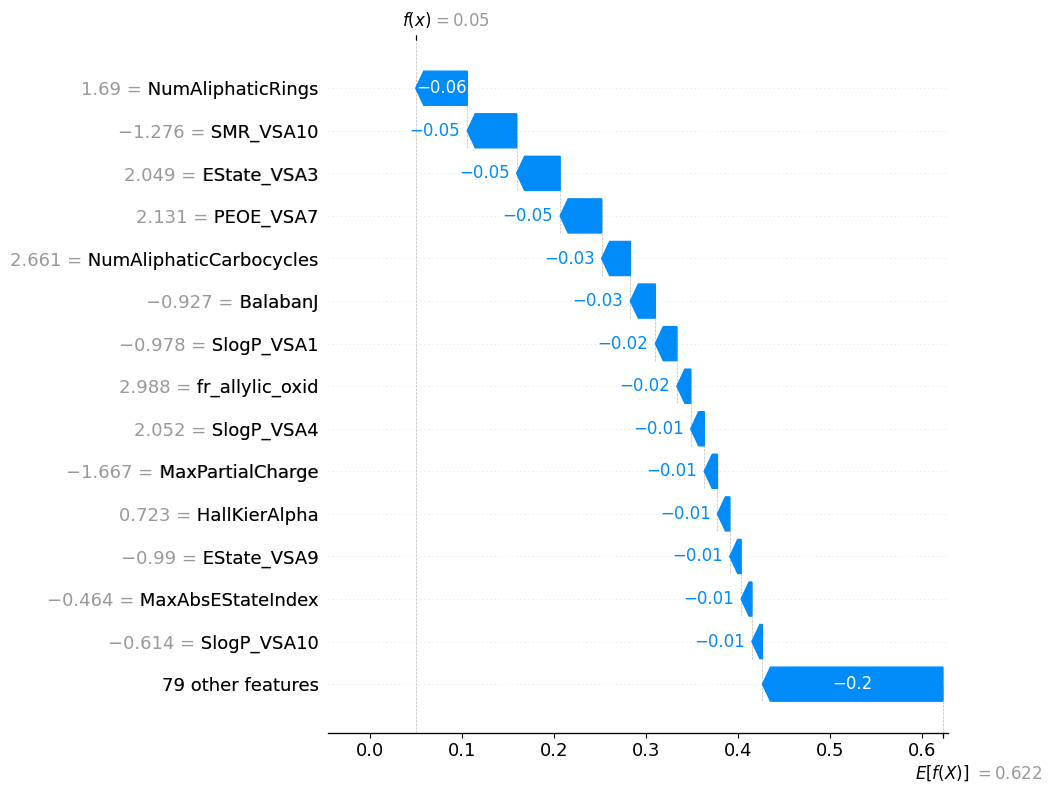


ROS
Base value: 0.5024
Total SHAP: -0.4424
Prediction: 0.0600


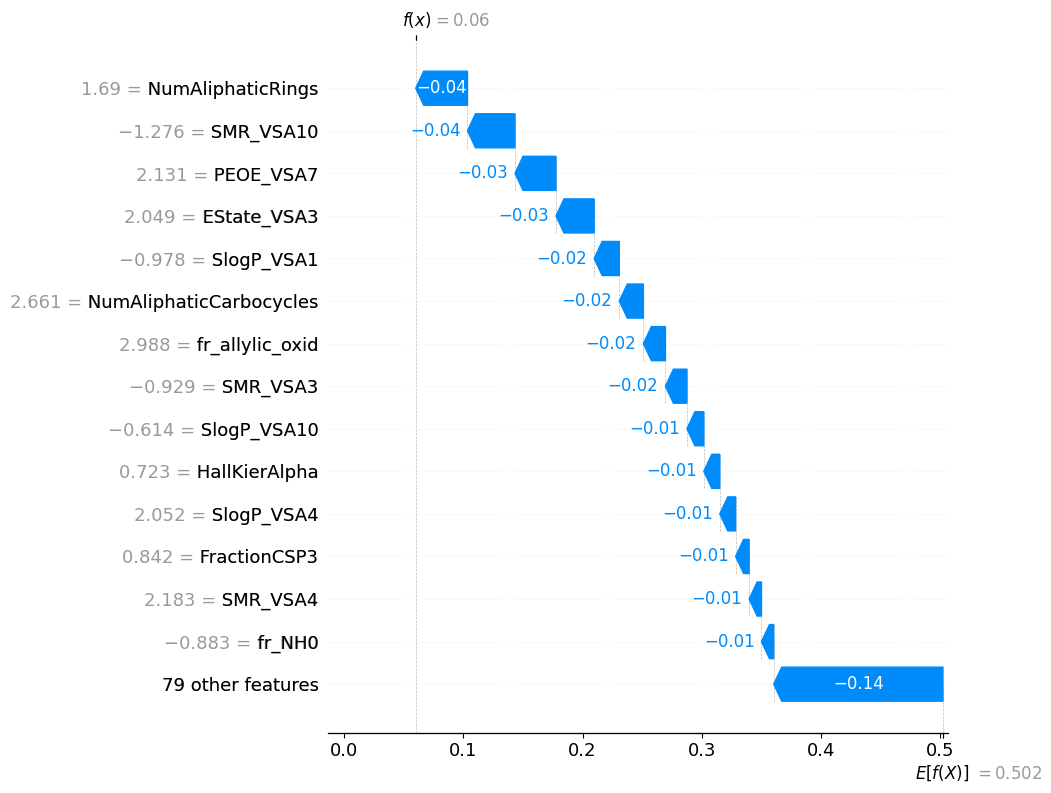


RUS
Base value: 0.5029
Total SHAP: -0.3729
Prediction: 0.1300


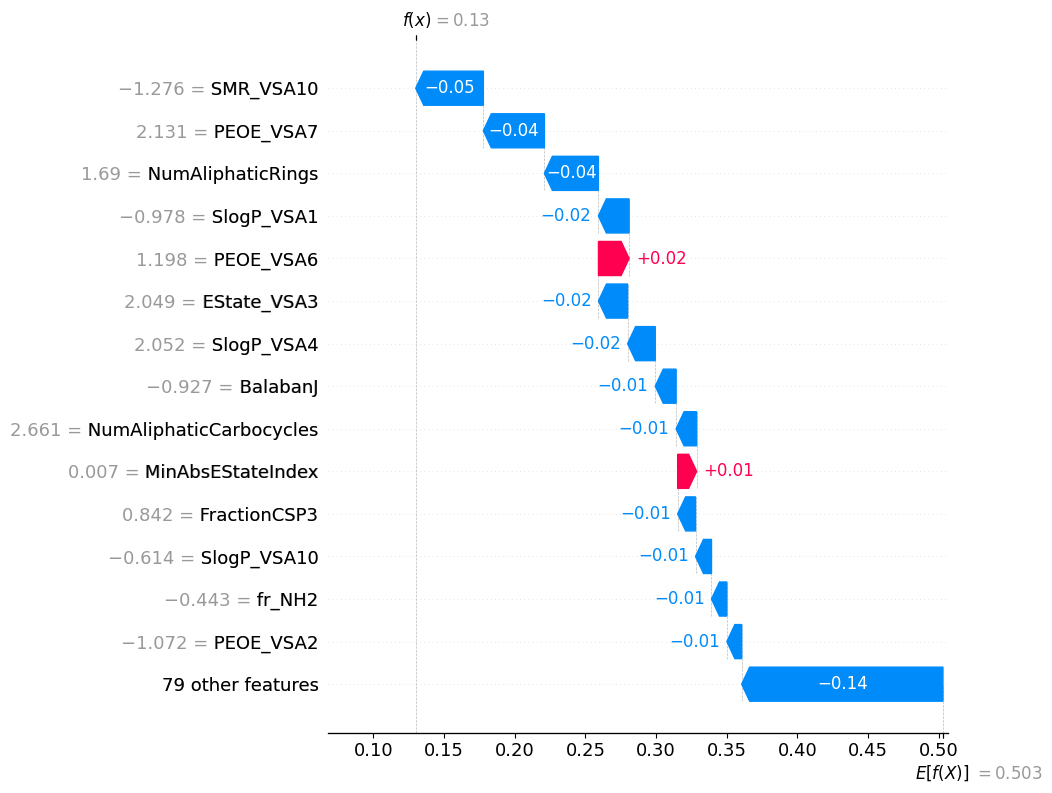

In [156]:
# 8.4 SHAP Local Explanation Comparison

models = {
    "Baseline": baseline_model,
    "SMOTE": model_rf_smote,
    "Class Weight": model_rf_weight,
    "ROS": ros_model,
    "RUS": rus_model
}

drug_idx = 0

for name, model in models.items():

    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_test_mi)

    if shap_values.values.ndim == 3:
        shap_positive = shap_values[:, :, 1]
    else:
        shap_positive = shap_values

    drug = shap_positive[drug_idx]

    base = float(drug.base_values)
    contribution = float(drug.values.sum())
    prediction = float(
        model.predict_proba(X_test_mi.iloc[[drug_idx]])[0, 1]
    )

    print(f"\n{name}")
    print(f"Base value: {base:.4f}")
    print(f"Total SHAP: {contribution:.4f}")
    print(f"Prediction: {prediction:.4f}")

    shap.plots.waterfall(
        drug,
        max_display=15
    )


Baseline
Predicted DIA probability: 0.06


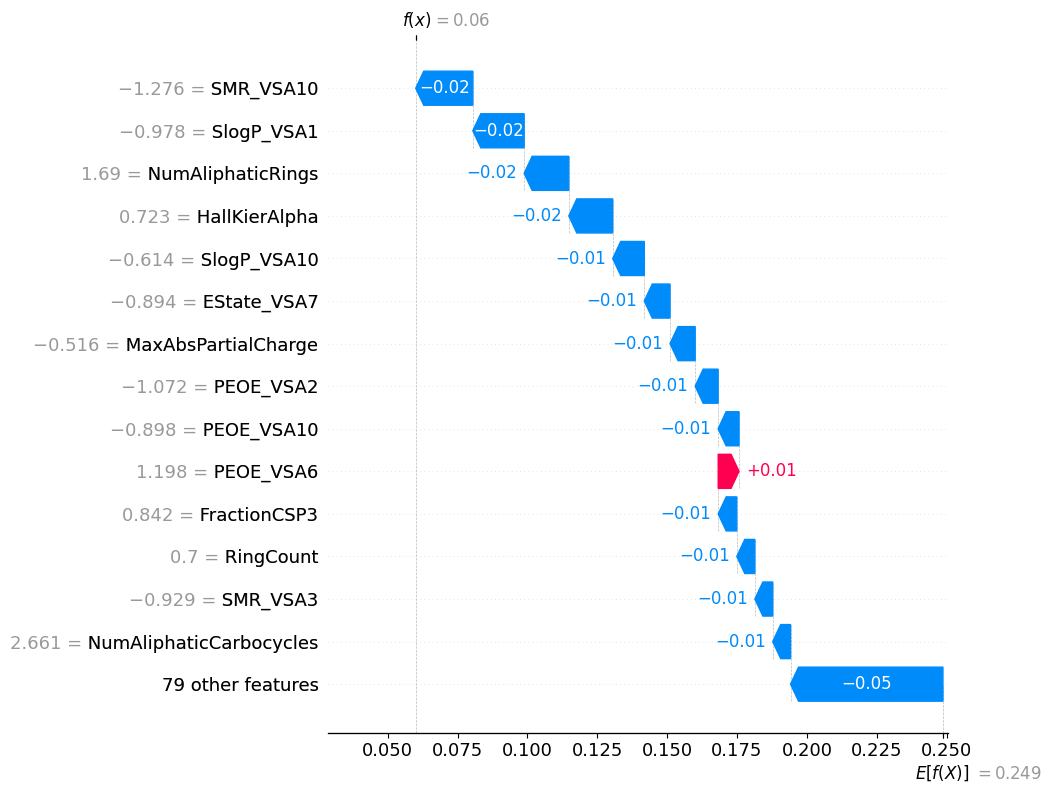


SMOTE
Predicted DIA probability: 0.11


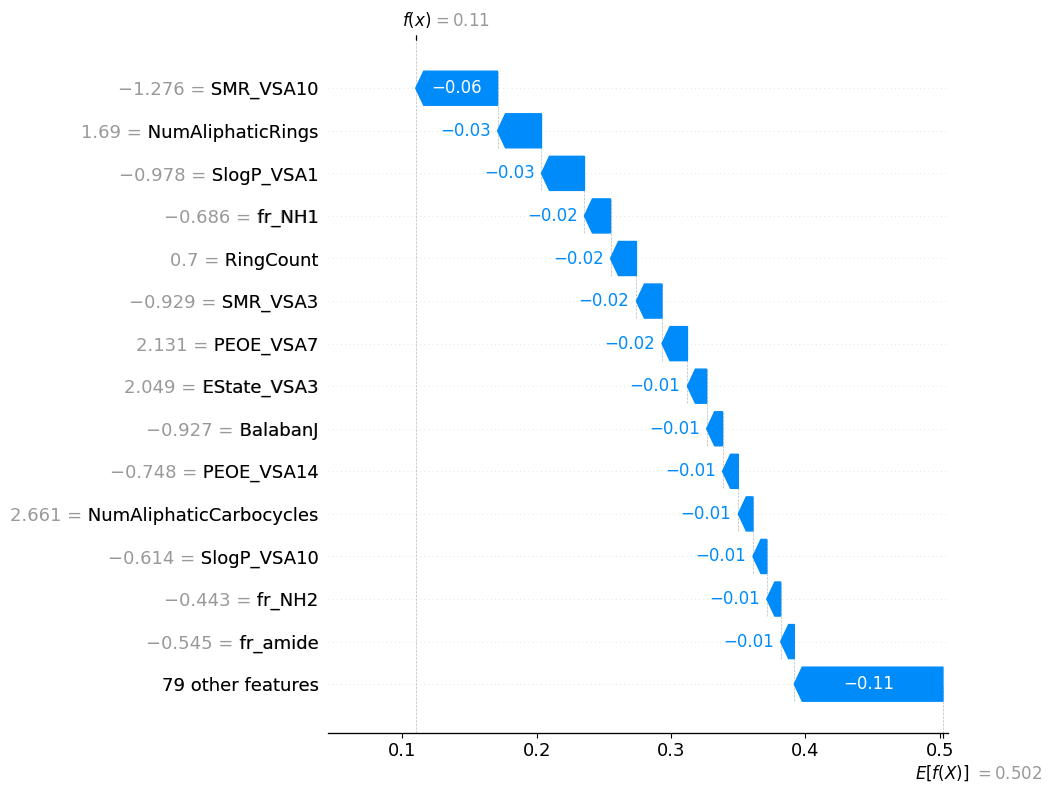


Class Weight
Predicted DIA probability: 0.05


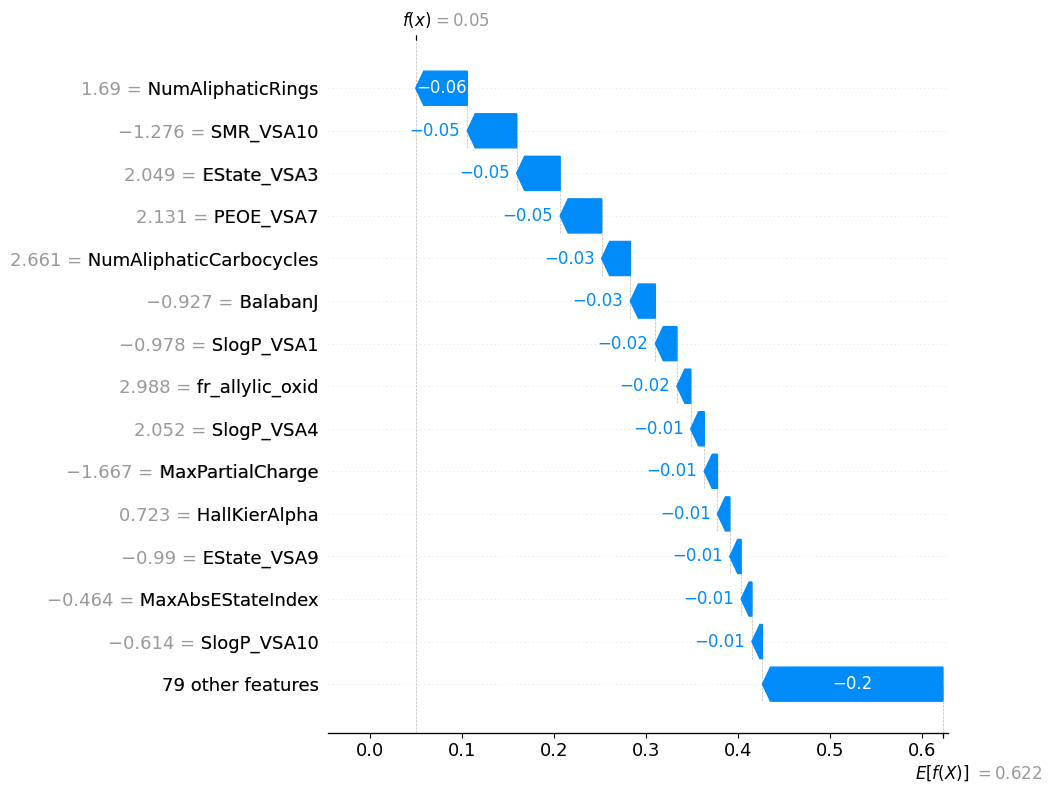


ROS
Predicted DIA probability: 0.06


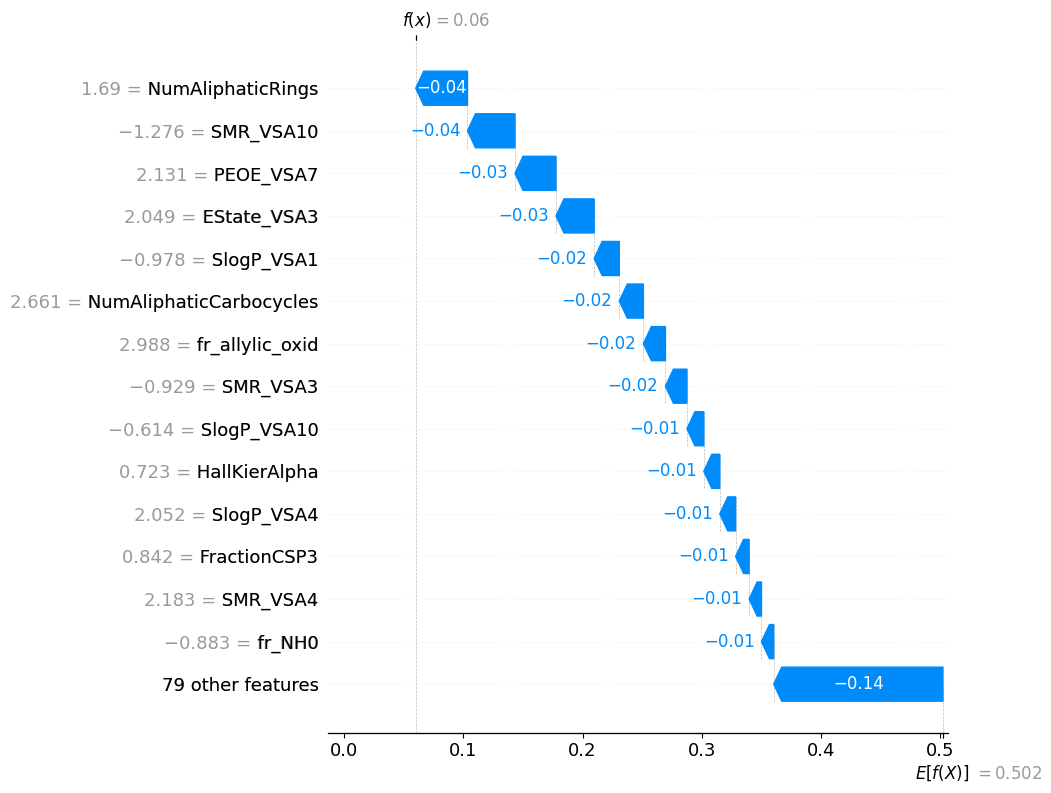


RUS
Predicted DIA probability: 0.13


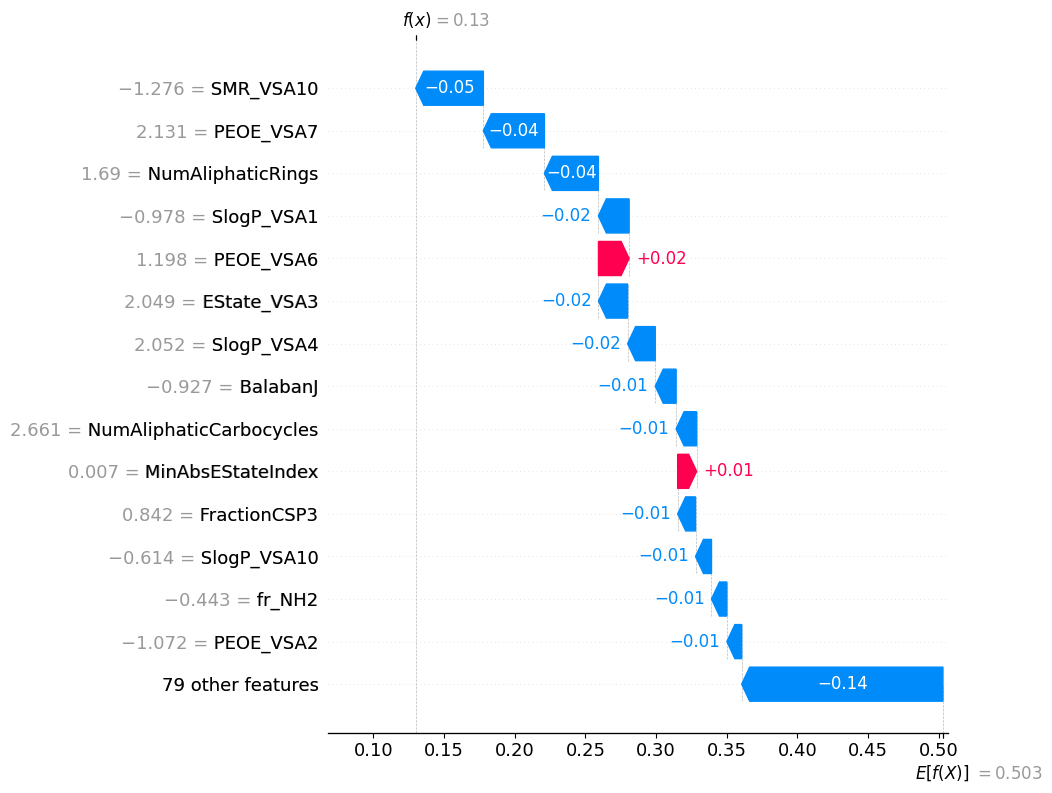

In [157]:
models = {
    "Baseline": baseline_model,
    "SMOTE": model_rf_smote,
    "Class Weight": model_rf_weight,
    "ROS": ros_model,
    "RUS": rus_model
}

drug_idx = 0

for name, model in models.items():

    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_test_mi)

    if shap_values.values.ndim == 3:
        shap_positive = shap_values[:, :, 1]
    else:
        shap_positive = shap_values

    print(f"\n{name}")
    print(
        "Predicted DIA probability:",
        model.predict_proba(X_test_mi.iloc[[drug_idx]])[0, 1]
    )

    shap.plots.waterfall(
        shap_positive[drug_idx],
        max_display=15
    )

In [158]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

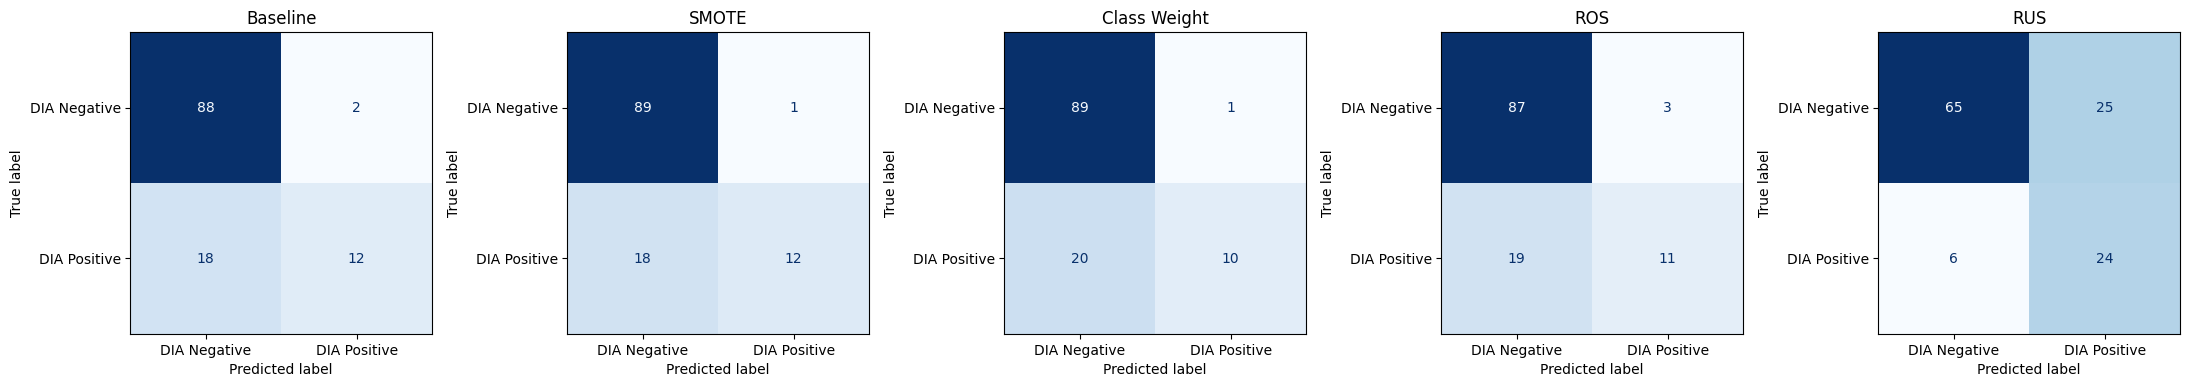

In [159]:
models = {
    "Baseline": baseline_model,
    "SMOTE": model_rf_smote,
    "Class Weight": model_rf_weight,
    "ROS": ros_model,
    "RUS": rus_model
}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (name, model) in zip(axes, models.items()):

    # Predict using the external test data
    y_pred = model.predict(X_test_mi)

    # Calculate confusion matrix
    cm = confusion_matrix(Ytest, y_pred, labels=[0, 1])

    # Draw confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["DIA Negative", "DIA Positive"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()